# A Diffusion Model for Synthetic Channel-Flow Fields

This notebook trains a **denoising diffusion probabilistic model (DDPM)** on
the channel-flow snapshots (`(y, x)` planes of the streamwise velocity `u`),
so that it can generate **new, synthetic fields** that look like real DNS
snapshots -- not a blurred average of them.

**Why not just train a regression network for this?** A deterministic model
trained with MSE (like a regression U-Net) learns the *conditional mean*
of the target given the input. For a genuinely stochastic system like
turbulence, that mean is not a physically realistic single realization -- it
is smoother and less structured than any actual snapshot, because it averages
over every plausible turbulent state consistent with the same conditioning
information. A diffusion model instead learns to **sample** from the true
distribution of fields, one realization at a time.

**What "respects the mean and standard deviation" means here, precisely.**
This notebook trains an **unconditional** diffusion model: it learns the
distribution of the whole ensemble of snapshots. If it has learned that
distribution well, then a large batch of *generated* samples should
reproduce the same $y$-dependent mean profile $U(y)$ and standard-deviation
profile $\sigma(y)$ as the *real* ensemble -- exactly the check performed in
Section 10 below. Note this is an ensemble-level property (many generated
samples vs. many real samples), not something guaranteed sample-by-sample.

**The DDPM idea, briefly.** Take a real field $x_0$ and progressively corrupt
it with Gaussian noise over $T$ steps until it becomes pure noise $x_T$
(the **forward process**, fixed, no learning involved). Train a network to
**reverse** this -- predict the noise that was added at each step -- so that,
starting from pure noise, repeatedly applying the trained denoiser
reconstructs a plausible new sample $x_0$ (the **reverse process**, this is
what generates new fields).


# Stage 1 — A diffusion model for synthetic channel-flow fields

**Portfolio project: can a generative model produce turbulent fields that are new, and still have the flow's statistics?**

A regression network trained with a mean-squared error returns the average of every field consistent with its input, which is smoother than any real turbulent snapshot. A denoising diffusion probabilistic model (DDPM) instead learns to draw new fields, one realisation at a time. This notebook trains one on 5,777 y–x planes of the streamwise velocity u from a direct numerical simulation of turbulent channel flow (Re_τ ≈ 125, 201 × 384 points, padded to 208 rows): a forward process adds Gaussian noise over T = 200 steps with a linear schedule, and a time-conditioned 2-D U-Net (508,785 weights) learns to predict that noise. Sampling runs the process backwards from noise. The notebook checks the mean and standard-deviation profiles of 64 generated fields; I solve its five experiments (a Gaussian baseline with no spatial structure, a denoiser conditioned on the wall shear stress, faster DDIM sampling, a cosine schedule and a longer chain, energy spectra), repeat every experiment training with the seeds 0, 1 and 2, and record a training animation.

**How it connects.** Stage 2 holds the generator to stricter terms: every statistic against 577 held-out fields the denoiser never saw, the two-point correlation and the probability density as well as the profiles, a test of whether it copies training fields, and the cost of sampling against quality.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, 2026-10-13, Apple GPU: one training step of the denoiser takes 87 ms there against 589 ms on the CPU). The 40-epoch training of the denoiser took 22 minutes, so it is one run (seed 0); the experiment trainings and samplers are repeated with three seeds at the end. Afterwards I changed only text for this repository: this cell and the paths cell, the path lines (planes from `../release_assets/u_yx_planes_h5/`, model to `../models/01_diffusion_channel_flow/`, tables to `../results/01_diffusion_channel_flow/`, animation to `../animations/01_*`), comments, labels and printed text. One quirk is kept as written: the markdown says the 7 padding rows sit at the centreline, but edge padding appends them at the top wall (`y[-1]`).

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
PLANES = Path("../release_assets/u_yx_planes_h5")   # the 5,777 planes, from the unet-turbulent-fields release (README)
for p in (Path("../models/01_diffusion_channel_flow/checkpoints"), Path("../results/01_diffusion_channel_flow/exercises"), Path("../animations")):
    p.mkdir(parents=True, exist_ok=True)
print("planes found:", len(list(PLANES.glob("P125_83pi.*.h5"))) if PLANES.is_dir() else 0)

In [1]:
# Device report. Apple GPU: one training step inside model.fit (batch 16, 208 x 384 fields, median of 30 steps after
# 10 warm-up; ../results/02_field_statistics_and_memorisation/device_timing_*.csv), CPU vs Apple GPU in ms: denoiser 588.6 vs 87.1,
# conditional denoiser (Ex 2) 596.8 vs 91.2 -> GPU. The 40-epoch training (13,000 steps) took 22 minutes in my run: one seed.
import tensorflow as tf, platform
print("TensorFlow", tf.__version__, "| Python", platform.python_version())
print("Physical devices:", tf.config.list_physical_devices())
print("GPU (Metal) visible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.18.1 | Python 3.12.14
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU (Metal) visible: True


# 1. Environment


In [2]:
# =========================================================
# Import libraries
# =========================================================

from pathlib import Path

import h5py
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

np.random.seed(0)
tf.random.set_seed(0)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.18.1


# 2. Optional: Google Colab Setup


In [3]:
# =========================================================
# Check whether we are running in Google Colab
# =========================================================

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive
    # [original] drive.mount("/content/drive")
    pass  # Google Drive is not mounted: the planes come from the local merged folder (see the data_dir cell)


Running in Google Colab: False


# 3. Load All Snapshots into a Single Array

Padding the wall-normal axis from `n_y=201` to
`208` (multiple of 16, needed for 4 levels of pooling in the U-Net denoiser)
using edge-padding -- the padded rows sit right at the channel centerline,
where the field is smooth, so duplicating the last row or two has minimal
physical impact. We crop back to `n_y=201` whenever we compute real physical
statistics later (Section 10).


In [4]:
# =========================================================
# Define data paths and load all snapshots
# =========================================================

if IN_COLAB:
    data_dir = Path("/content/drive/<Drive folder>/diffusion-channel-flow-fields/release_assets/u_yx_planes_h5")
else:
    data_dir = Path("../release_assets/u_yx_planes_h5")  # path line: the planes from the release (README)

file_glob = "P125_83pi.*.h5"
matched_files = sorted(data_dir.glob(file_glob))
print("Number of matched files:", len(matched_files))

with h5py.File(matched_files[0], "r") as f:
    n_y_raw, n_x = f["u"].shape
    y_grid = f["y"][:]

pad_amount = 16 - (n_y_raw % 16) if (n_y_raw % 16) != 0 else 0
n_y_padded = n_y_raw + pad_amount
print(f"n_y_raw={n_y_raw} -> padded to n_y_padded={n_y_padded} (pad_amount={pad_amount})")
print(f"n_x={n_x} (already a multiple of 16: {n_x % 16 == 0})")

fields = np.zeros((len(matched_files), n_y_padded, n_x, 1), dtype=np.float32)

for i, file_path in enumerate(matched_files):
    with h5py.File(file_path, "r") as f:
        u = f["u"][:]
    if pad_amount > 0:
        u = np.pad(u, ((0, pad_amount), (0, 0)), mode="edge")
    fields[i, :, :, 0] = u

    if (i + 1) % 500 == 0:
        print(f"Loaded {i + 1} / {len(matched_files)} files")

print("\nfields shape:", fields.shape)


Number of matched files: 5777
n_y_raw=201 -> padded to n_y_padded=208 (pad_amount=7)
n_x=384 (already a multiple of 16: True)


Loaded 500 / 5777 files


Loaded 1000 / 5777 files


Loaded 1500 / 5777 files


Loaded 2000 / 5777 files


...

Loaded 4000 / 5777 files


Loaded 4500 / 5777 files


Loaded 5000 / 5777 files


Loaded 5500 / 5777 files



fields shape: (5777, 208, 384, 1)


# 4. Normalize and Split


In [5]:
# =========================================================
# Normalize and split into train/validation
# =========================================================

data_mean = fields.mean()
data_std = fields.std() + 1e-8

fields_norm = (fields - data_mean) / data_std

n_val = max(1, int(0.1 * fields_norm.shape[0]))
rng = np.random.default_rng(0)
perm = rng.permutation(fields_norm.shape[0])
val_idx, trn_idx = perm[:n_val], perm[n_val:]

fields_trn = fields_norm[trn_idx]
fields_val = fields_norm[val_idx]

print("Training snapshots:  ", fields_trn.shape[0])
print("Validation snapshots:", fields_val.shape[0])
print("data_mean, data_std:", data_mean, data_std)


Training snapshots:   5200
Validation snapshots: 577
data_mean, data_std: 0.78406733 0.34096804


# 5. The Forward Diffusion Process

A linear noise schedule $\beta_t$ over $T$ steps, with the usual DDPM
shortcut that lets us jump directly to any noise level $t$ without simulating
all the intermediate steps:

$$
x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\, \epsilon,
\qquad \epsilon \sim \mathcal{N}(0, I),
$$

where $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s \le t} \alpha_s$.
$T$ is kept modest (a few hundred steps) to keep training and sampling
tractable for a teaching notebook -- state-of-the-art diffusion models often
use $T$ in the thousands.


In [6]:
# =========================================================
# Linear beta schedule and precomputed diffusion constants
# =========================================================

T = 200

beta = np.linspace(1e-4, 0.02, T).astype(np.float32)
alpha = 1.0 - beta
alpha_bar = np.cumprod(alpha).astype(np.float32)

sqrt_alpha_bar = np.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = np.sqrt(1.0 - alpha_bar)

print("T:", T)
print("alpha_bar[0], alpha_bar[-1]:", alpha_bar[0], alpha_bar[-1])


def q_sample(x0, t_idx, noise):
    """
    Forward process: sample x_t given x_0, a timestep index per example, and
    pre-drawn noise. t_idx: int array, shape (batch,).
    """
    sab = sqrt_alpha_bar[t_idx].reshape(-1, 1, 1, 1)
    somab = sqrt_one_minus_alpha_bar[t_idx].reshape(-1, 1, 1, 1)
    return sab * x0 + somab * noise


T: 200
alpha_bar[0], alpha_bar[-1]: 0.9999 0.13218278


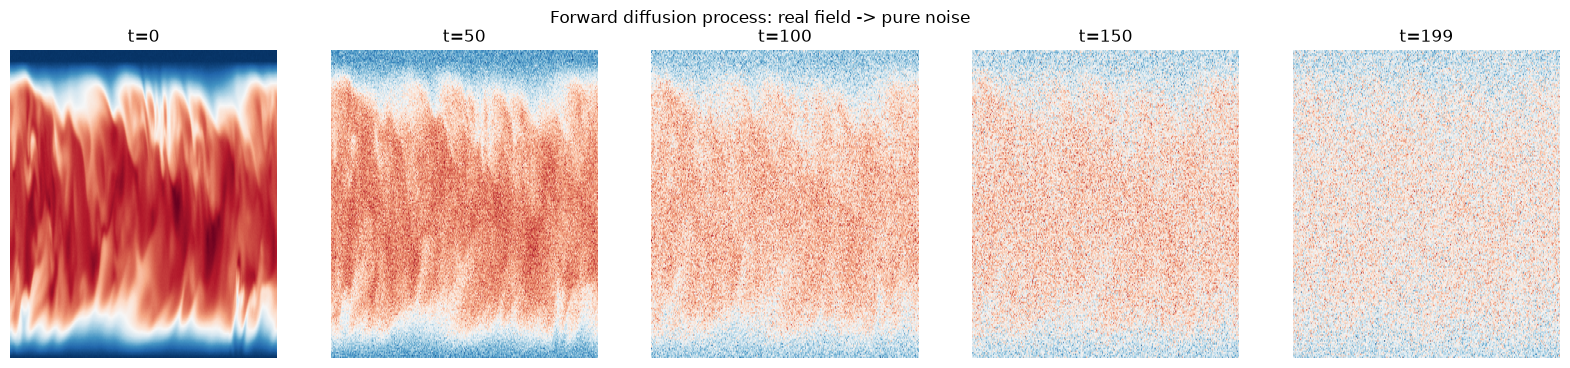

In [7]:
# =========================================================
# Visualize the forward process on one real snapshot
# =========================================================

x0_demo = fields_trn[0:1]
demo_steps = [0, T // 4, T // 2, (3 * T) // 4, T - 1]

fig, ax = plt.subplots(1, len(demo_steps), figsize=(4 * len(demo_steps), 4))

for i, t in enumerate(demo_steps):
    noise = np.random.normal(size=x0_demo.shape).astype(np.float32)
    xt = q_sample(x0_demo, np.array([t]), noise)
    ax[i].imshow(xt[0, :, :, 0], cmap="RdBu_r", aspect="auto", origin="lower")
    ax[i].set_title(f"t={t}")
    ax[i].axis("off")

fig.suptitle("Forward diffusion process: real field -> pure noise")
plt.show()


# 6. The Denoiser: a Time-Conditioned 2D U-Net

The usual U-Net skeleton (encoder/bottleneck/decoder,
skip connections), with one addition: a **sinusoidal timestep embedding**
(the same style used in Transformers for position, applied here to the
diffusion timestep $t$ instead), injected into every convolutional block so
the network knows *how noisy* its input currently is.


In [8]:
# =========================================================
# Sinusoidal timestep embedding
# =========================================================

def sinusoidal_embedding(t, dim=64):
    """t: float tensor, shape (batch,). Returns shape (batch, dim)."""
    half = dim // 2
    freqs = tf.exp(-tf.math.log(10000.0) * tf.range(half, dtype=tf.float32) / half)
    args = tf.cast(t[:, None], tf.float32) * freqs[None, :]
    return tf.concat([tf.sin(args), tf.cos(args)], axis=-1)


In [9]:
# =========================================================
# Time-conditioned U-Net building blocks
# =========================================================


def conv_block_t(x, t_emb, filters, kernel_size=3, activation="relu", padding="same"):
    x = tf.keras.layers.Conv2D(filters, kernel_size, padding=padding,
                                kernel_initializer="he_normal")(x)

    # Project the time embedding to `filters` channels and add it (broadcast
    # over height/width) -- this is how the network learns "how noisy am I".
    t_proj = tf.keras.layers.Dense(filters)(t_emb)
    t_proj = tf.keras.layers.Reshape((1, 1, filters))(t_proj)
    x = tf.keras.layers.Add()([x, t_proj])
    x = tf.keras.layers.Activation(activation)(x)

    x = tf.keras.layers.Conv2D(filters, kernel_size, activation=activation,
                                padding=padding, kernel_initializer="he_normal")(x)
    return x


def encoder_block_t(x, t_emb, filters):
    skip = conv_block_t(x, t_emb, filters)
    down = tf.keras.layers.MaxPooling2D(pool_size=2)(skip)
    return skip, down


def decoder_block_t(x, skip, t_emb, filters):
    x = tf.keras.layers.Conv2DTranspose(filters, kernel_size=2, strides=2, padding="same")(x)
    x = tf.keras.layers.Concatenate()([x, skip])
    x = conv_block_t(x, t_emb, filters)
    return x


In [10]:
# =========================================================
# Assemble the noise-prediction U-Net
# =========================================================

def create_denoiser(input_shape, base_filters=16, time_emb_dim=64):
    image_input = tf.keras.layers.Input(shape=input_shape, name="noisy_field")
    t_input = tf.keras.layers.Input(shape=(), name="timestep")

    t_emb = tf.keras.layers.Lambda(
        lambda t: sinusoidal_embedding(t, dim=time_emb_dim)
    )(t_input)
    t_emb = tf.keras.layers.Dense(time_emb_dim, activation="relu")(t_emb)

    skip1, x = encoder_block_t(image_input, t_emb, base_filters)
    skip2, x = encoder_block_t(x, t_emb, base_filters * 2)
    skip3, x = encoder_block_t(x, t_emb, base_filters * 4)

    x = conv_block_t(x, t_emb, base_filters * 8)

    x = decoder_block_t(x, skip3, t_emb, base_filters * 4)
    x = decoder_block_t(x, skip2, t_emb, base_filters * 2)
    x = decoder_block_t(x, skip1, t_emb, base_filters)

    noise_pred = tf.keras.layers.Conv2D(1, kernel_size=1, activation="linear")(x)

    return tf.keras.Model([image_input, t_input], noise_pred, name="Denoiser")


input_shape = (n_y_padded, n_x, 1)
denoiser = create_denoiser(input_shape, base_filters=16)
denoiser.summary()


2026-10-13 23:07:51.332146: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 23:07:51.332169: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 23:07:51.332176: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791947271.332186 52194645 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791947271.332202 52194645 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "Denoiser"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ timestep            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 64)        │          0 │ timestep[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noisy_field         │ (None, 208, 384,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │      1,040 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 208, 384,  │        160 │ noisy_field[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 16)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 208, 384,  │          0 │ conv2d[0][0],     │
│                     │ 16)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 208, 384,  │          0 │ add[0][0]         │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 208, 384,  │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 104, 192,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 104, 192,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 1, 32)  │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 104, 192,  │          0 │ conv2d_2[0][0],   │
│                     │ 32)               │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 104, 192,  │          0 │ add_1[0][0]       │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 104, 192,  │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 52, 96,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      4,160 │ dense[0][0]     

 Total params: 508,785 (1.94 MB)

 Trainable params: 508,785 (1.94 MB)

 Non-trainable params: 0 (0.00 B)

# 7. Training: Predict the Noise

For each batch: draw a random timestep $t$ per sample, draw random noise
$\epsilon$, form $x_t$ via `q_sample`, and train the network to predict
$\epsilon$ from $(x_t, t)$ -- a plain MSE regression. A custom `train_step`
is used (as for a VAE) since the random $t$/noise sampling has to
happen fresh every batch, not as a fixed target loaded from disk.


**Hook before the training cell.** The training loop calls `ex_loop_hook(loss)` after every step (one added call). Every half epoch the hook stores the per-step losses so far and generates 32 fields from the **same fixed noise** with the base denoiser; **for the snapshots only**, sampling uses the deterministic DDIM sampler with 20 steps instead of the 200-step DDPM sampler, so the overhead stays small. The fixed noise comes from its own generator (`default_rng(123)`) and DDIM draws no random numbers, so the base training is unchanged. Every 5 epochs the hook also writes the denoiser's weights to `../models/01_diffusion_channel_flow/checkpoints/`.

In [11]:
import time
from pathlib import Path
EX_CKPT = Path("../models/01_diffusion_channel_flow/checkpoints"); EX_CKPT.mkdir(parents=True, exist_ok=True)
ANIM_N = 32                                               # fields per snapshot (profiles); 3 are displayed
ANIM_DDIM_STEPS = 20
anim_ab = alpha_bar.astype(np.float64)
anim_ts = np.unique(np.linspace(0, T - 1, ANIM_DDIM_STEPS).round().astype(int))[::-1]
anim_noise = tf.constant(np.random.default_rng(123).standard_normal((ANIM_N, n_y_padded, n_x, 1)).astype(np.float32))

anim_eps = tf.function(lambda a, b: denoiser([a, b], training=False))


def anim_ddim_fixed_noise():
    x = anim_noise
    for i, t in enumerate(anim_ts):
        eps = anim_eps(x, tf.fill((ANIM_N,), float(t)))
        x0 = (x - float(np.sqrt(1 - anim_ab[t])) * eps) / float(np.sqrt(anim_ab[t]))
        abp = anim_ab[anim_ts[i + 1]] if i + 1 < len(anim_ts) else 1.0
        x = float(np.sqrt(abp)) * x0 + float(np.sqrt(1 - abp)) * eps
    return x.numpy()[:, :n_y_raw, :, 0] * data_std + data_mean


anim_snaps, anim_losses, anim_step, anim_snap_secs = [], [], 0, 0.0


def anim_snap():
    g = anim_ddim_fixed_noise()
    anim_snaps.append(dict(step=anim_step, epoch=anim_step / steps_per_epoch, losses=list(anim_losses),
                           fields=g[:3].copy(), mean=g.mean(axis=(0, 2)), std=g.std(axis=(0, 2))))



def ex_loop_hook(loss):
    global anim_step, anim_snap_secs
    anim_losses.append(float(loss)); anim_step += 1
    every = max(1, steps_per_epoch // 2)
    if anim_step == 1 or anim_step % every == 0:
        ts_ = time.time(); anim_snap(); anim_snap_secs += time.time() - ts_
    if anim_step % (5 * steps_per_epoch) == 0:
        denoiser.save_weights(EX_CKPT / f"diffusion_denoiser_epoch{anim_step // steps_per_epoch:03d}.weights.h5")

In [12]:
# =========================================================
# Custom training loop
# =========================================================

optimizer = tf.keras.optimizers.Adam(learning_rate=2e-4)
batch_size = 16
epochs = 40
steps_per_epoch = max(1, fields_trn.shape[0] // batch_size)


@tf.function
def train_step(x0_batch):
    batch_n = tf.shape(x0_batch)[0]
    t_idx = tf.random.uniform((batch_n,), minval=0, maxval=T, dtype=tf.int32)
    noise = tf.random.normal(tf.shape(x0_batch))

    sab = tf.gather(sqrt_alpha_bar, t_idx)[:, None, None, None]
    somab = tf.gather(sqrt_one_minus_alpha_bar, t_idx)[:, None, None, None]
    xt = sab * x0_batch + somab * noise

    with tf.GradientTape() as tape:
        noise_pred = denoiser([xt, tf.cast(t_idx, tf.float32)], training=True)
        loss = tf.reduce_mean(tf.square(noise - noise_pred))

    grads = tape.gradient(loss, denoiser.trainable_weights)
    optimizer.apply_gradients(zip(grads, denoiser.trainable_weights))
    return loss


loss_history = []

for epoch in range(epochs):
    perm = np.random.permutation(fields_trn.shape[0])
    epoch_losses = []

    for step in range(steps_per_epoch):
        batch_idx = perm[step * batch_size:(step + 1) * batch_size]
        x0_batch = fields_trn[batch_idx]
        loss = train_step(x0_batch)
        # [original] epoch_losses.append(float(loss))
        epoch_losses.append(float(loss)); ex_loop_hook(loss)  # added: animation snapshot every half epoch, checkpoint every 5 epochs

    mean_loss = np.mean(epoch_losses)
    loss_history.append(mean_loss)
    print(f"Epoch {epoch + 1:3d}/{epochs}  loss={mean_loss:.4f}")


2026-10-13 23:07:52.519793: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Epoch   1/40  loss=0.4176


Epoch   2/40  loss=0.1299


Epoch   3/40  loss=0.0873


Epoch   4/40  loss=0.0712


...

Epoch  36/40  loss=0.0160


Epoch  37/40  loss=0.0162


Epoch  38/40  loss=0.0176


Epoch  39/40  loss=0.0156


Epoch  40/40  loss=0.0162


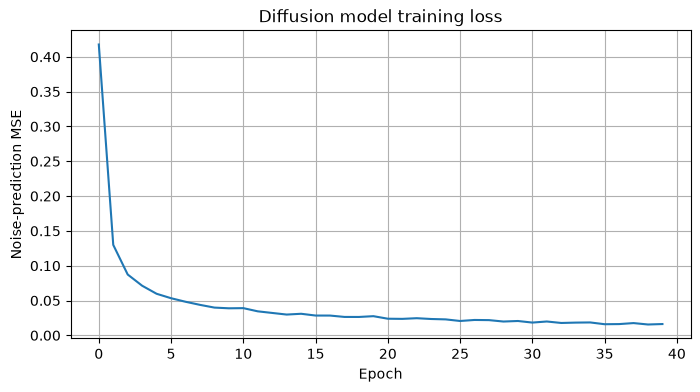

Denoiser saved.


In [13]:
# =========================================================
# Plot training loss and save the model
# =========================================================

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Noise-prediction MSE")
plt.title("Diffusion model training loss")
plt.grid(True)
plt.show()

model_dir = Path("../models/01_diffusion_channel_flow")
model_dir.mkdir(exist_ok=True)
denoiser.save(model_dir / "diffusion_denoiser.keras")
print("Denoiser saved.")


# 8. Sampling: Generating New Fields

The DDPM reverse step, iterated from $t=T-1$ down to $t=0$, starting from
pure Gaussian noise:

$$
x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,
\epsilon_\theta(x_t, t)\right) + \sigma_t z, \qquad z \sim \mathcal{N}(0, I) \text{ if } t>0 \text{ else } 0
$$

This loop calls the network $T$ times per batch of samples -- slow compared
to a single forward pass, which is the well-known cost of DDPM sampling
(Experiment 3 asks about speeding this up).


In [14]:
# =========================================================
# DDPM sampling loop
# =========================================================

def sample_ddpm(n_samples, verbose_every=50):
    x = tf.random.normal((n_samples, n_y_padded, n_x, 1))

    for t in reversed(range(T)):
        t_batch = tf.fill((n_samples,), float(t))
        noise_pred = denoiser([x, t_batch], training=False)

        alpha_t = alpha[t]
        alpha_bar_t = alpha_bar[t]
        beta_t = beta[t]

        coef = beta_t / np.sqrt(1.0 - alpha_bar_t)
        mean = (x - coef * noise_pred) / np.sqrt(alpha_t)

        if t > 0:
            z = tf.random.normal(tf.shape(x))
            sigma_t = np.sqrt(beta_t)
            x = mean + sigma_t * z
        else:
            x = mean

        if (t + 1) % verbose_every == 0 or t == 0:
            print(f"Sampling step t={t}")

    return x.numpy()


n_generated = 8
generated_norm = sample_ddpm(n_generated)
generated = generated_norm * data_std + data_mean

print("\nGenerated fields shape:", generated.shape)


Sampling step t=199


Sampling step t=149


Sampling step t=99


Sampling step t=49


Sampling step t=0

Generated fields shape: (8, 208, 384, 1)


# 9. Visualize Generated Fields Next to Real Ones


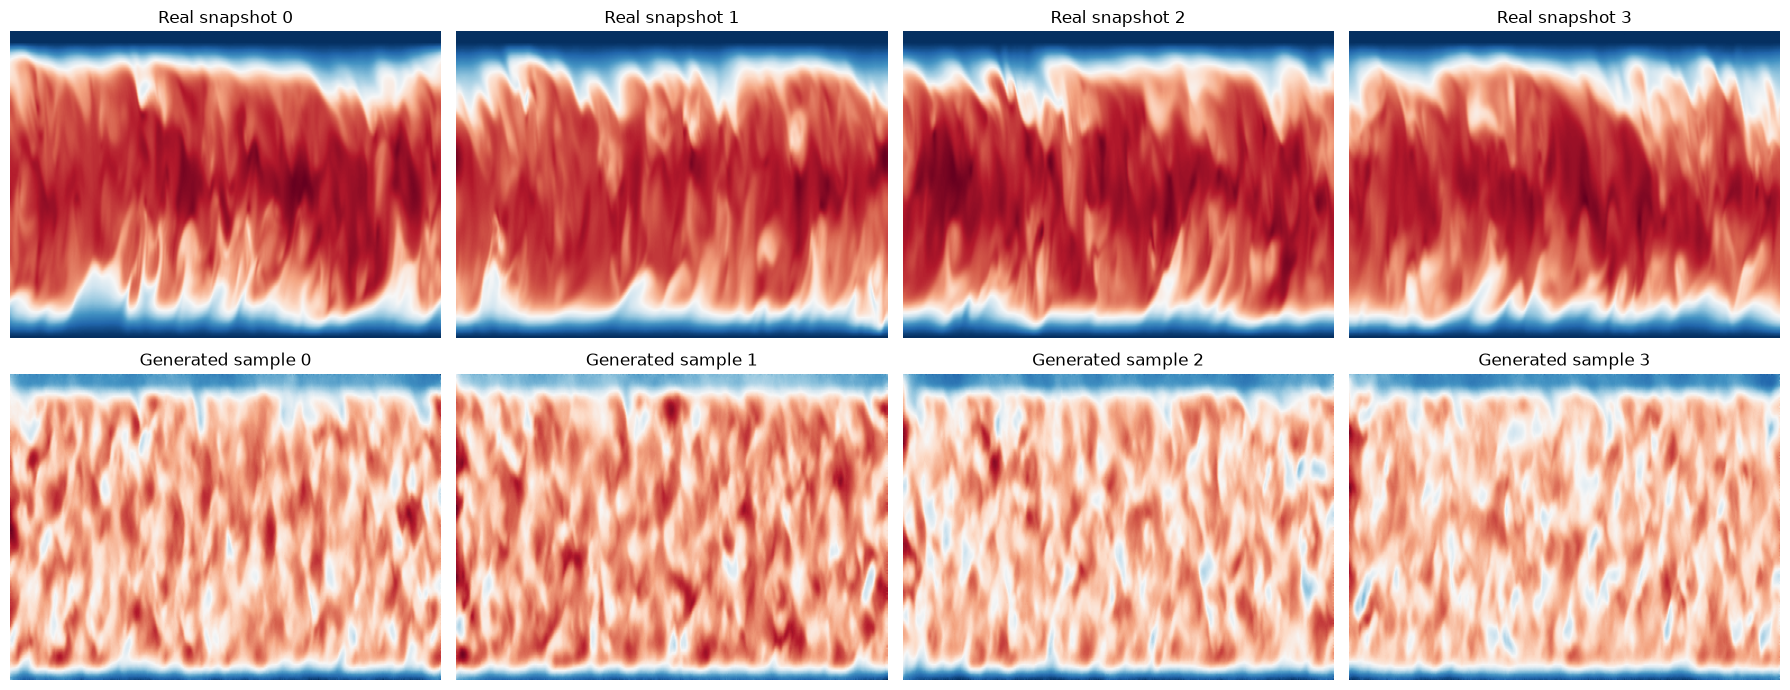

In [15]:
# =========================================================
# Compare a few generated fields to real validation snapshots
# =========================================================

fields_val_phys = fields_val * data_std + data_mean

fig, ax = plt.subplots(2, 4, figsize=(18, 7))

for i in range(4):
    ax[0, i].imshow(fields_val_phys[i, :, :, 0], cmap="RdBu_r", aspect="auto", origin="lower")
    ax[0, i].set_title(f"Real snapshot {i}")
    ax[0, i].axis("off")

    ax[1, i].imshow(generated[i, :, :, 0], cmap="RdBu_r", aspect="auto", origin="lower")
    ax[1, i].set_title(f"Generated sample {i}")
    ax[1, i].axis("off")

fig.tight_layout()
plt.show()


# 10. Does It Respect the Mean and Standard Deviation?

The actual check the notebook was built for: compare the $y$-dependent mean
and standard-deviation profiles of a **large batch of generated samples**
against the same profiles computed from the **real training ensemble**
(cropping the padded rows back to the real `n_y=201` first).

Generating enough samples for a fair statistical comparison means running
the sampling loop many times -- this can take a while with `T=200` steps per
batch; reduce `n_stats_samples` if needed for a quick check.


Sampling step t=199


Sampling step t=99


Sampling step t=0


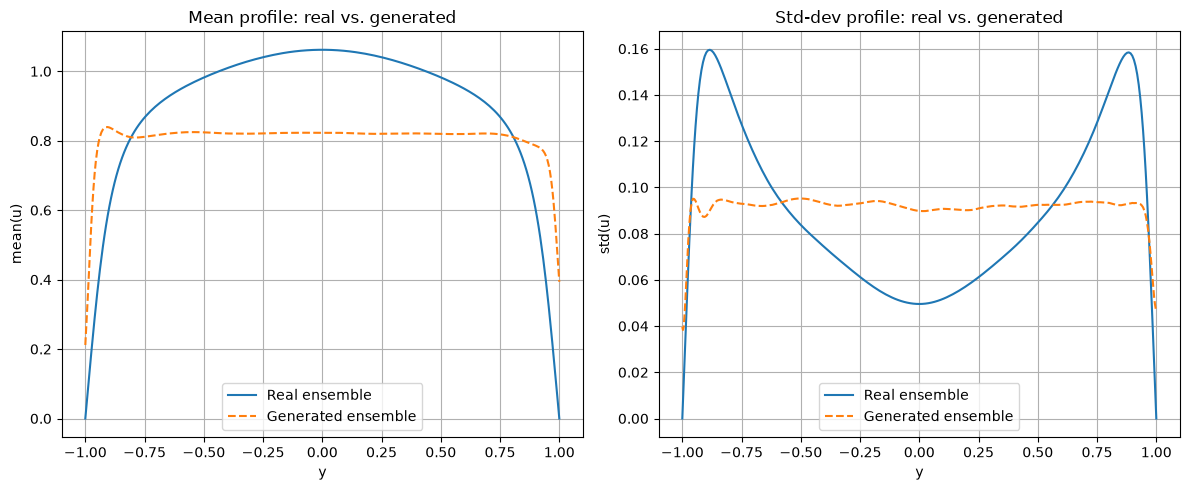

Mean-profile MAE: 0.19203866
Std-profile MAE:  0.03030438


In [16]:
# =========================================================
# Generate a larger batch and compare y-profiles of mean and std
# =========================================================

n_stats_samples = 64
generated_stats_norm = sample_ddpm(n_stats_samples, verbose_every=100)
generated_stats = generated_stats_norm * data_std + data_mean

# Crop the padded rows back off before computing physical statistics
generated_stats_cropped = generated_stats[:, :n_y_raw, :, 0]
real_cropped = fields[:, :n_y_raw, :, 0]  # fields = original unpadded-region physical data

mean_profile_real = real_cropped.mean(axis=(0, 2))
std_profile_real = real_cropped.std(axis=(0, 2))

mean_profile_gen = generated_stats_cropped.mean(axis=(0, 2))
std_profile_gen = generated_stats_cropped.std(axis=(0, 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(y_grid, mean_profile_real, label="Real ensemble")
ax[0].plot(y_grid, mean_profile_gen, label="Generated ensemble", linestyle="--")
ax[0].set_xlabel("y")
ax[0].set_ylabel("mean(u)")
ax[0].set_title("Mean profile: real vs. generated")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(y_grid, std_profile_real, label="Real ensemble")
ax[1].plot(y_grid, std_profile_gen, label="Generated ensemble", linestyle="--")
ax[1].set_xlabel("y")
ax[1].set_ylabel("std(u)")
ax[1].set_title("Std-dev profile: real vs. generated")
ax[1].legend()
ax[1].grid(True)

fig.tight_layout()
plt.show()

print("Mean-profile MAE:", np.mean(np.abs(mean_profile_real - mean_profile_gen)))
print("Std-profile MAE: ", np.mean(np.abs(std_profile_real - std_profile_gen)))


# 11. Experiments

## Experiment 1 -- Naive Gaussian baseline

Before trusting the diffusion model, compare it against the simplest
possible generator: for each pixel `(y, x)`, sample independently from
`N(mean_profile_real[y], std_profile_real[y])` (no spatial correlation at
all). This trivially matches the mean/std profiles by construction -- so
Section 10's check alone doesn't prove the diffusion model learned anything
beyond first-order statistics. Compare the *visual* structure (Section 9) and,
if you can, a two-point correlation or spectrum, between the Gaussian
baseline and the diffusion samples, to see what the diffusion model captures
that the naive baseline cannot.

---

## Experiment 2 -- Condition on wall-shear stress

Make this a **conditional** diffusion model: append $\tau_w(x)$ (the wall
gradient of u) as an extra input channel to the denoiser (broadcast along
$y$), so sampling is conditioned on a given wall-stress profile instead of
being fully unconditional. This connects directly to predicting near-wall
flow from the wall, but now producing a plausible *distribution* of near-wall fields consistent with
$\tau_w(x)$, rather than one deterministic prediction.

---

## Experiment 3 -- Faster sampling with DDIM

Section 8's sampling loop calls the network $T=200$ times per batch.
Implement the deterministic DDIM sampler (same trained `denoiser`, different
update rule, skipping most timesteps) and compare sample quality and speed
against the full $T$-step DDPM sampler used here.

---

## Experiment 4 -- Larger $T$ / better schedule

Try a cosine noise schedule instead of the linear one in Section 5, and/or
increase `T`. Does the mean/std match from Section 10 improve, and by how
much does training/sampling time increase?

---

## Experiment 5 -- Energy spectrum comparison

Compute the streamwise energy spectrum (1D FFT in $x$, averaged over
snapshots and over $y$-bands) for both the real ensemble and a batch of
generated samples. Do the generated fields reproduce the real energy
cascade across scales, or only the large scales?


# Experiment solutions
The five experiments of Section 11, solved with this notebook's data (`fields`, `fields_trn`, `fields_val`, `val_idx`, `trn_idx`, `y_grid`), normalisation (`data_mean`, `data_std`), schedule (`beta`, `T = 200`), denoiser builder (`create_denoiser`), trained `denoiser` and the 64 generated samples of Section 10 (`generated_stats`). Experiment 1 compares a per-row Gaussian baseline with the diffusion samples through streamwise and wall-normal two-point correlations; Experiment 2 trains a conditional denoiser with $\tau_w(x)$ as a second input channel; Experiment 3 adds a deterministic DDIM sampler for the trained denoiser; Experiment 4 trains linear-$T{=}200$, cosine-$T{=}200$ and cosine-$T{=}500$ models; Experiment 5 compares streamwise energy spectra in four $y^+$ bands. **Reduced budget:** the four extra trainings (Experiments 2 and 4) use 10 epochs each instead of the base 40, with all other settings unchanged (Adam 2e-4, batch 16, same U-Net). **Compute plan:** the four 10-epoch trainings together cost about one base training (estimated 20–35 min on the Apple GPU for 13,000 steps of a 4-level U-Net on 208 × 384 fields), plus about 90,000 sample-network evaluations for sampling (estimated 5–15 min); total estimate 30–50 min, well inside 2.5 h even at 3× slower.

In [17]:
# Shared helpers for all exercises
import time
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import tensorflow as tf
import matplotlib.pyplot as plt

ex_dir = Path("../results/01_diffusion_channel_flow/exercises"); ex_dir.mkdir(exist_ok=True)

with h5py.File(matched_files[0], "r") as ex_f:
    ex_attrs = dict(ex_f.attrs)
ex_Lx = float(2 * np.pi / ex_attrs["alp"]) if "alp" in ex_attrs else 8 * np.pi
ex_dx = ex_Lx / n_x
ex_half = (y_grid[-1] - y_grid[0]) / 2.0
ex_retau = 125.0                                           # nominal Re_tau of P125_83pi
ex_yp = np.minimum(y_grid - y_grid[0], y_grid[-1] - y_grid) / ex_half * ex_retau   # y+ from the nearest wall
ex_yp_bot = (y_grid - y_grid[0]) / ex_half * ex_retau                             # y+ from the bottom wall
ex_j15 = int(np.argmin(np.abs(ex_yp_bot - 15.0)))           # bottom-wall row closest to y+ = 15
ex_j10 = int(np.argmin(np.abs(ex_yp_bot - 10.0)))
ex_jc = n_y_raw // 2                                       # centreline row
ex_bands = [(0, 10), (10, 30), (30, 70), (70, 126)]          # y+ bands (distance to the nearest wall)
ex_band_rows = [np.where((ex_yp >= lo) & (ex_yp < hi))[0] for lo, hi in ex_bands]
print(f"Lx={ex_Lx:.3f}, dx={ex_dx:.4f}; row y+=15 -> j={ex_j15} (y+={ex_yp_bot[ex_j15]:.1f}), "
      f"y+=10 -> j={ex_j10} (y+={ex_yp_bot[ex_j10]:.1f}); rows per band:", [len(r) for r in ex_band_rows])


def ex_phys(s_norm):
    """Normalised padded samples (N, 208, n_x, 1) -> physical, cropped (N, 201, n_x)."""
    return np.asarray(s_norm)[:, :n_y_raw, :, 0] * data_std + data_mean


def ex_spec(u, chunk=128):
    """Streamwise energy spectrum per row: mean over samples of |FFT_x(u')|^2 / n_x^2, u' = u - <u>(y)."""
    mu = u.mean(axis=(0, 2), keepdims=True)
    acc = np.zeros((u.shape[1], n_x // 2 + 1))
    for s in range(0, u.shape[0], chunk):
        acc += (np.abs(np.fft.rfft(u[s:s + chunk] - mu, axis=-1)) ** 2).sum(axis=0)
    return acc / u.shape[0] / n_x ** 2


def ex_band_spec(E):
    return np.stack([E[r].mean(axis=0) for r in ex_band_rows])        # (4 bands, n_x//2+1)


def ex_corr_x(u, j):
    """Streamwise two-point correlation R_uu(r) at row j (periodic, via FFT)."""
    up = u[:, j, :] - u[:, j, :].mean()
    P = (np.abs(np.fft.rfft(up, axis=-1)) ** 2).mean(axis=0)
    R = np.fft.irfft(P, n=n_x)
    return (R / R[0])[: n_x // 2 + 1]


def ex_corr_y(u, j0):
    """Wall-normal correlation coefficient of u' at zero streamwise separation, reference row j0."""
    up = u - u.mean(axis=(0, 2), keepdims=True)
    ref = up[:, j0, :]
    num = (up * ref[:, None, :]).mean(axis=(0, 2))
    return num / (up.std(axis=(0, 2)) * ref.std() + 1e-12)


def ex_first_below(R, level=0.5):
    k = np.where(R < level)[0]
    return int(k[0]) if len(k) else len(R)


def ex_tau_bottom(u, noslip=False):
    """tau_w(x) = du/dy at y[0], one-sided 2nd-order formula on the non-uniform grid ."""
    h1, h2 = y_grid[1] - y_grid[0], y_grid[2] - y_grid[1]
    c0 = -(2 * h1 + h2) / (h1 * (h1 + h2)); c1 = (h1 + h2) / (h1 * h2); c2 = -h1 / (h2 * (h1 + h2))
    u0 = 0.0 if noslip else u[:, 0, :]
    return c0 * u0 + c1 * u[:, 1, :] + c2 * u[:, 2, :]


ex_rng = np.random.default_rng(0)
ex_real = real_cropped[np.sort(ex_rng.choice(real_cropped.shape[0], 512, replace=False))]   # 512 real snapshots
ex_Eb_real = ex_band_spec(ex_spec(ex_real))


def ex_quality(u):
    """Mean/std-profile MAE vs the full real ensemble and log-spectral distance (4 bands, all modes >= 1)."""
    Eb = ex_band_spec(ex_spec(u))
    lsd = float(np.sqrt(np.mean(np.log10(Eb[:, 1:] / ex_Eb_real[:, 1:]) ** 2)))
    return dict(mean_mae=float(np.mean(np.abs(u.mean(axis=(0, 2)) - mean_profile_real))),
                std_mae=float(np.mean(np.abs(u.std(axis=(0, 2)) - std_profile_real))), lsd=lsd)


# Generic sampler (DDPM with the original DDPM update rule, optional x0 clipping; or deterministic DDIM)
ex_fn_cache = {}


def ex_call(model, inp, t):
    f = ex_fn_cache.get(id(model))
    if f is None:
        f = tf.function(lambda a, b: model([a, b], training=False), reduce_retracing=True)
        ex_fn_cache[id(model)] = f
    return f(inp, t)


def ex_sample(model, beta_, n, seed=0, method="ddpm", steps=50, cond=None, x0_clip=None, chunk=64):
    beta_ = np.asarray(beta_, np.float64); alpha_ = 1.0 - beta_; ab = np.cumprod(alpha_); T_ = len(beta_)
    gen = tf.random.Generator.from_seed(seed)
    out = []
    for s in range(0, n, chunk):
        m = min(chunk, n - s)
        x = gen.normal((m, n_y_padded, n_x, 1))
        c_img = None if cond is None else tf.broadcast_to(
            tf.constant(cond[s:s + m], tf.float32)[:, None, :, None], (m, n_y_padded, n_x, 1))

        def eps_fn(x, t):
            inp = x if c_img is None else tf.concat([x, c_img], axis=-1)
            return ex_call(model, inp, tf.fill((m,), float(t)))

        if method == "ddpm":
            for t in reversed(range(T_)):
                eps = eps_fn(x, t)
                if x0_clip is None:      # exactly the original DDPM update
                    mean = (x - float(beta_[t] / np.sqrt(1 - ab[t])) * eps) / float(np.sqrt(alpha_[t]))
                else:                    # same mean written through a clipped x0 estimate
                    x0 = tf.clip_by_value((x - float(np.sqrt(1 - ab[t])) * eps) / float(np.sqrt(ab[t])), *x0_clip)
                    abp = ab[t - 1] if t > 0 else 1.0
                    mean = (float(np.sqrt(abp) * beta_[t] / (1 - ab[t])) * x0
                            + float(np.sqrt(alpha_[t]) * (1 - abp) / (1 - ab[t])) * x)
                x = mean + float(np.sqrt(beta_[t])) * gen.normal(tf.shape(x)) if t > 0 else mean
        else:                            # DDIM, eta = 0
            ts = np.unique(np.linspace(0, T_ - 1, steps).round().astype(int))[::-1]
            for i, t in enumerate(ts):
                eps = eps_fn(x, t)
                x0 = (x - float(np.sqrt(1 - ab[t])) * eps) / float(np.sqrt(ab[t]))
                if x0_clip is not None:
                    x0 = tf.clip_by_value(x0, *x0_clip)
                abp = ab[ts[i + 1]] if i + 1 < len(ts) else 1.0
                x = float(np.sqrt(abp)) * x0 + float(np.sqrt(1 - abp)) * eps
        out.append(x.numpy())
    return np.concatenate(out)


# Generic trainer: a copy of the training loop (Adam 2e-4, batch 16, MSE on the noise), any schedule, optional condition
def ex_train(model, beta_, epochs, cond=None, seed=0, lr=2e-4, label=""):
    ab = np.cumprod(1.0 - np.asarray(beta_, np.float64)).astype(np.float32)
    sab_c, somab_c, T_ = tf.constant(np.sqrt(ab)), tf.constant(np.sqrt(1.0 - ab)), len(beta_)
    opt = tf.keras.optimizers.Adam(learning_rate=lr)
    use_cond = cond is not None

    @tf.function
    def step(x0, c):
        bn = tf.shape(x0)[0]
        t_idx = tf.random.uniform((bn,), minval=0, maxval=T_, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(x0))
        xt = tf.gather(sab_c, t_idx)[:, None, None, None] * x0 + tf.gather(somab_c, t_idx)[:, None, None, None] * noise
        xin = tf.concat([xt, tf.broadcast_to(c[:, None, :, None], tf.shape(xt))], axis=-1) if use_cond else xt
        with tf.GradientTape() as tape:
            pred = model([xin, tf.cast(t_idx, tf.float32)], training=True)
            loss = tf.reduce_mean(tf.square(noise - pred))
        grads = tape.gradient(loss, model.trainable_weights)
        opt.apply_gradients(zip(grads, model.trainable_weights))
        return loss

    rng = np.random.default_rng(seed); tf.random.set_seed(seed)
    dummy = np.zeros((batch_size, n_x), np.float32)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        p = rng.permutation(fields_trn.shape[0]); ls = []
        for k in range(steps_per_epoch):
            bi = p[k * batch_size:(k + 1) * batch_size]
            ls.append(float(step(fields_trn[bi], cond[bi] if use_cond else dummy)))
        hist.append(float(np.mean(ls)))
        print(f"[{label}] epoch {ep + 1}/{epochs} loss={hist[-1]:.4f}")
    return hist, time.time() - t0


ex_clip = (float(fields_trn.min()), float(fields_trn.max()))
ex_gen = generated_stats[:, :n_y_raw, :, 0]                 # 64 DDPM samples of Section 10, physical, cropped
print("Real subset:", ex_real.shape, " diffusion samples:", ex_gen.shape, " x0 clip range (normalised):", ex_clip)

Lx=25.133, dx=0.0654; row y+=15 -> j=23 (y+=15.4), y+=10 -> j=17 (y+=10.1); rows per band: [34, 40, 58, 69]


Real subset: (512, 201, 384)  diffusion samples: (64, 201, 384)  x0 clip range (normalised): (-2.3800928592681885, 1.4700335264205933)


## Experiment 1 — solution
The baseline draws every pixel independently from $\mathcal N(\bar u(y), \sigma(y)^2)$ with the real profiles, 64 samples like Section 10. It matches the mean and standard-deviation profiles by construction, so the comparison is made on spatial structure: the streamwise two-point correlation $R_{uu}(r)$ at $y^+\approx 15$ and at the centreline, and the wall-normal correlation of $u'$ with the $y^+\approx15$ row, for the real ensemble (512 snapshots), the 64 diffusion samples and the 64 baseline samples. The separation at which $R_{uu}$ first drops below 0.5 is used as a correlation length.

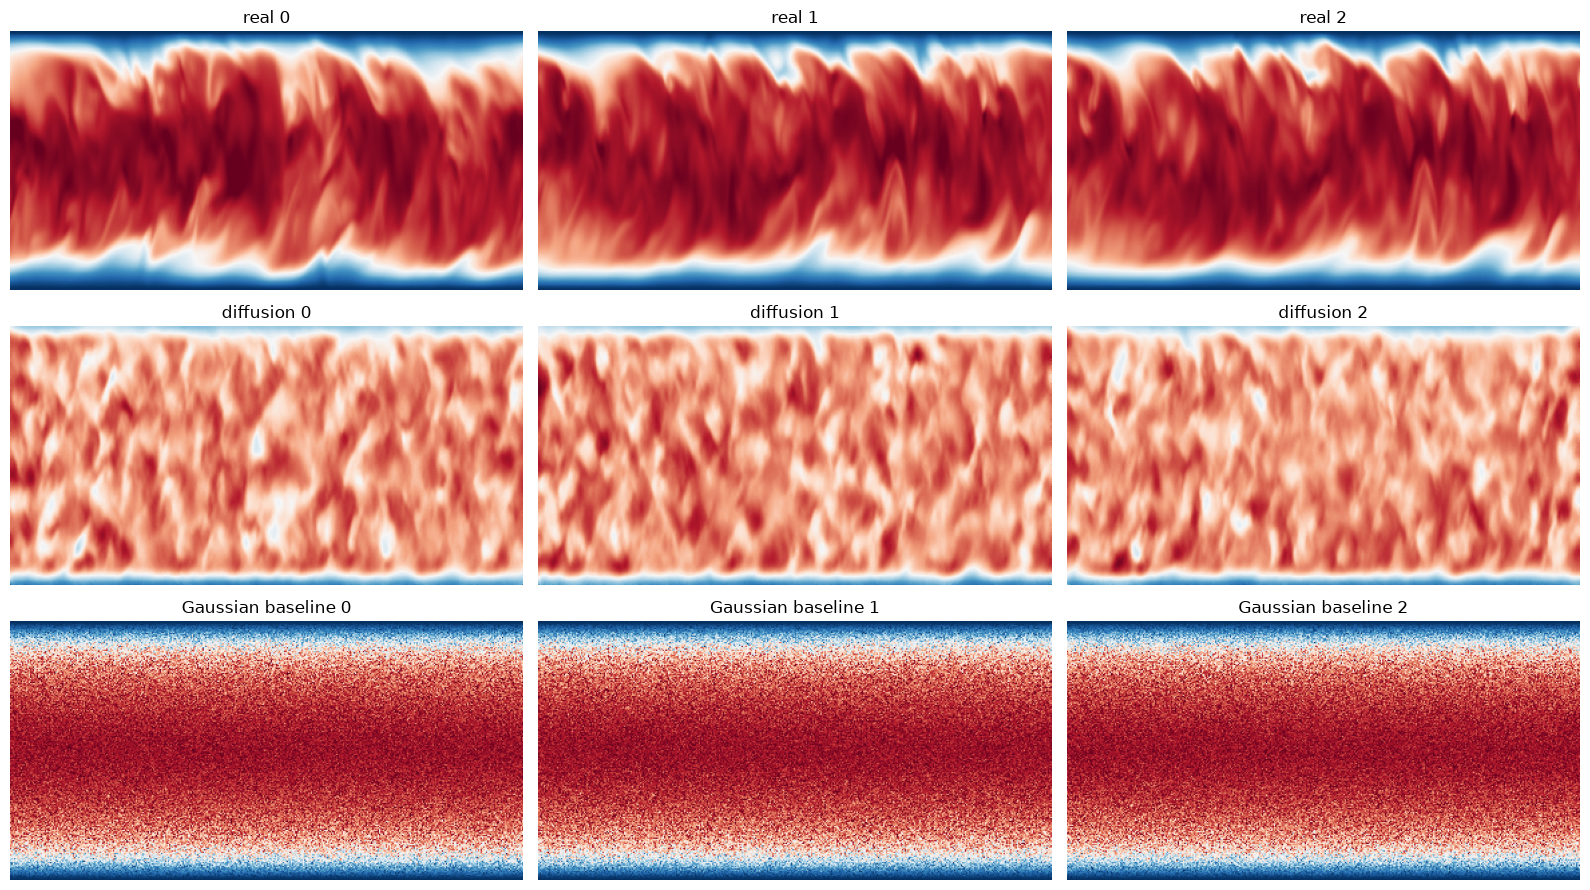

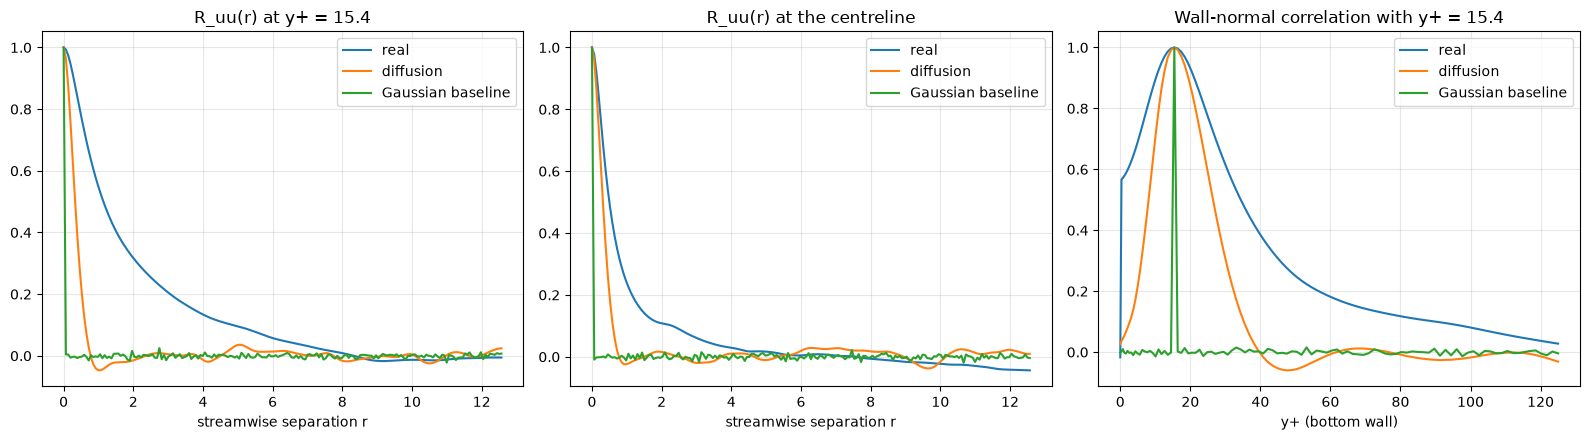

         ensemble  Lx_R05_yplus15  Lx_R05_centre  Ry_gt05_extent_yplus  mean_mae  std_mae    lsd
             real          1.1781         0.5236               34.0105    0.0011   0.0005 0.0000
        diffusion          0.3927         0.3272               17.4782    0.1920   0.0303 6.1221
Gaussian baseline          0.0654         0.0654                0.0000    0.0005   0.0003 7.6879
Result (Exercise 1): length where R_uu<0.5 at y+~15: real 1.178, diffusion 0.393, Gaussian 0.065 (dx=0.065); wall-normal extent R>0.5: real 34.0, diffusion 17.5, Gaussian 0.0 y+; std-profile MAE diffusion 0.0303 vs Gaussian 0.0003; log-spectral distance diffusion 6.122 vs Gaussian 7.688


In [18]:
ex1_rng = np.random.default_rng(1)
ex1_gauss = (mean_profile_real[None, :, None]
             + std_profile_real[None, :, None] * ex1_rng.standard_normal((64, n_y_raw, n_x))).astype(np.float32)
ex1_sets = {"real": ex_real, "diffusion": ex_gen, "Gaussian baseline": ex1_gauss}

fig, ax = plt.subplots(3, 3, figsize=(16, 9))
ex_vmin, ex_vmax = np.percentile(ex_real[:16], [1, 99])
for r, (name, u) in enumerate(ex1_sets.items()):
    for c in range(3):
        ax[r, c].imshow(u[c], cmap="RdBu_r", aspect="auto", origin="lower", vmin=ex_vmin, vmax=ex_vmax)
        ax[r, c].set_title(f"{name} {c}"); ax[r, c].axis("off")
fig.tight_layout(); fig.savefig(ex_dir / "ex1_fields.png", dpi=100); plt.show()

ex1_rows = []
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ex_r = np.arange(n_x // 2 + 1) * ex_dx
for name, u in ex1_sets.items():
    R15, Rc, Ry = ex_corr_x(u, ex_j15), ex_corr_x(u, ex_jc), ex_corr_y(u, ex_j15)
    ax[0].plot(ex_r, R15, label=name); ax[1].plot(ex_r, Rc, label=name)
    ax[2].plot(ex_yp_bot[: n_y_raw // 2 + 1], Ry[: n_y_raw // 2 + 1], label=name)
    above = np.where(Ry[: n_y_raw // 2 + 1] > 0.5)[0]
    ex1_rows.append(dict(ensemble=name, Lx_R05_yplus15=ex_first_below(R15) * ex_dx,
                         Lx_R05_centre=ex_first_below(Rc) * ex_dx,
                         Ry_gt05_extent_yplus=float(ex_yp_bot[above.max()] - ex_yp_bot[above.min()]),
                         **ex_quality(u)))
ax[0].set_title(f"R_uu(r) at y+ = {ex_yp_bot[ex_j15]:.1f}"); ax[1].set_title("R_uu(r) at the centreline")
ax[2].set_title(f"Wall-normal correlation with y+ = {ex_yp_bot[ex_j15]:.1f}")
for a in ax[:2]: a.set_xlabel("streamwise separation r")
ax[2].set_xlabel("y+ (bottom wall)")
for a in ax: a.grid(alpha=0.3); a.legend()
fig.tight_layout(); fig.savefig(ex_dir / "ex1_correlations.png", dpi=100); plt.show()

ex1_df = pd.DataFrame(ex1_rows); ex1_df.to_csv(ex_dir / "ex1_baseline_vs_diffusion.csv", index=False)
print(ex1_df.round(4).to_string(index=False))
ex1_d = ex1_df.set_index("ensemble")
print(f"Result (Exercise 1): length where R_uu<0.5 at y+~15: real {ex1_d.loc['real','Lx_R05_yplus15']:.3f}, "
      f"diffusion {ex1_d.loc['diffusion','Lx_R05_yplus15']:.3f}, Gaussian {ex1_d.loc['Gaussian baseline','Lx_R05_yplus15']:.3f} (dx={ex_dx:.3f}); "
      f"wall-normal extent R>0.5: real {ex1_d.loc['real','Ry_gt05_extent_yplus']:.1f}, diffusion {ex1_d.loc['diffusion','Ry_gt05_extent_yplus']:.1f}, "
      f"Gaussian {ex1_d.loc['Gaussian baseline','Ry_gt05_extent_yplus']:.1f} y+; std-profile MAE diffusion {ex1_d.loc['diffusion','std_mae']:.4f} "
      f"vs Gaussian {ex1_d.loc['Gaussian baseline','std_mae']:.4f}; log-spectral distance diffusion {ex1_d.loc['diffusion','lsd']:.3f} vs Gaussian {ex1_d.loc['Gaussian baseline','lsd']:.3f}")

## Experiment 2 — solution
$\tau_w(x)$ is the wall gradient $\partial u/\partial y$ at the bottom wall, from the one-sided second-order formula on the stretched grid (stored units). The bottom wall is used because the edge-padding adds its 7 extra rows at the top wall (`y[-1]`), not at the centreline. $\tau_w$ is normalised by its own mean and standard deviation and given to the denoiser as a second input channel, broadcast along $y$; the U-Net is the base (`create_denoiser` with a 2-channel input). **Reduced budget:** 10 epochs instead of 40, other settings as in the base training. For four validation snapshots, eight conditional samples each are drawn with the full 200-step DDPM sampler; the wall stress recomputed from each sample is compared with the conditioning profile (correlation coefficient and RMS error relative to the profile's standard deviation), against the same measure for the 64 unconditional samples of Section 10.

tau_w: mean 7.6449, std 2.6791


[cond] epoch 1/10 loss=0.4505


[cond] epoch 2/10 loss=0.1479


[cond] epoch 3/10 loss=0.0992


[cond] epoch 4/10 loss=0.0779


...

[cond] epoch 7/10 loss=0.0508


[cond] epoch 8/10 loss=0.0476


[cond] epoch 9/10 loss=0.0407


[cond] epoch 10/10 loss=0.0403


                       corr  rel_rmse
model         noslip                 
conditional   False   0.309     8.068
              True    0.089    30.953
unconditional False   0.000     3.055
              True    0.063    44.163


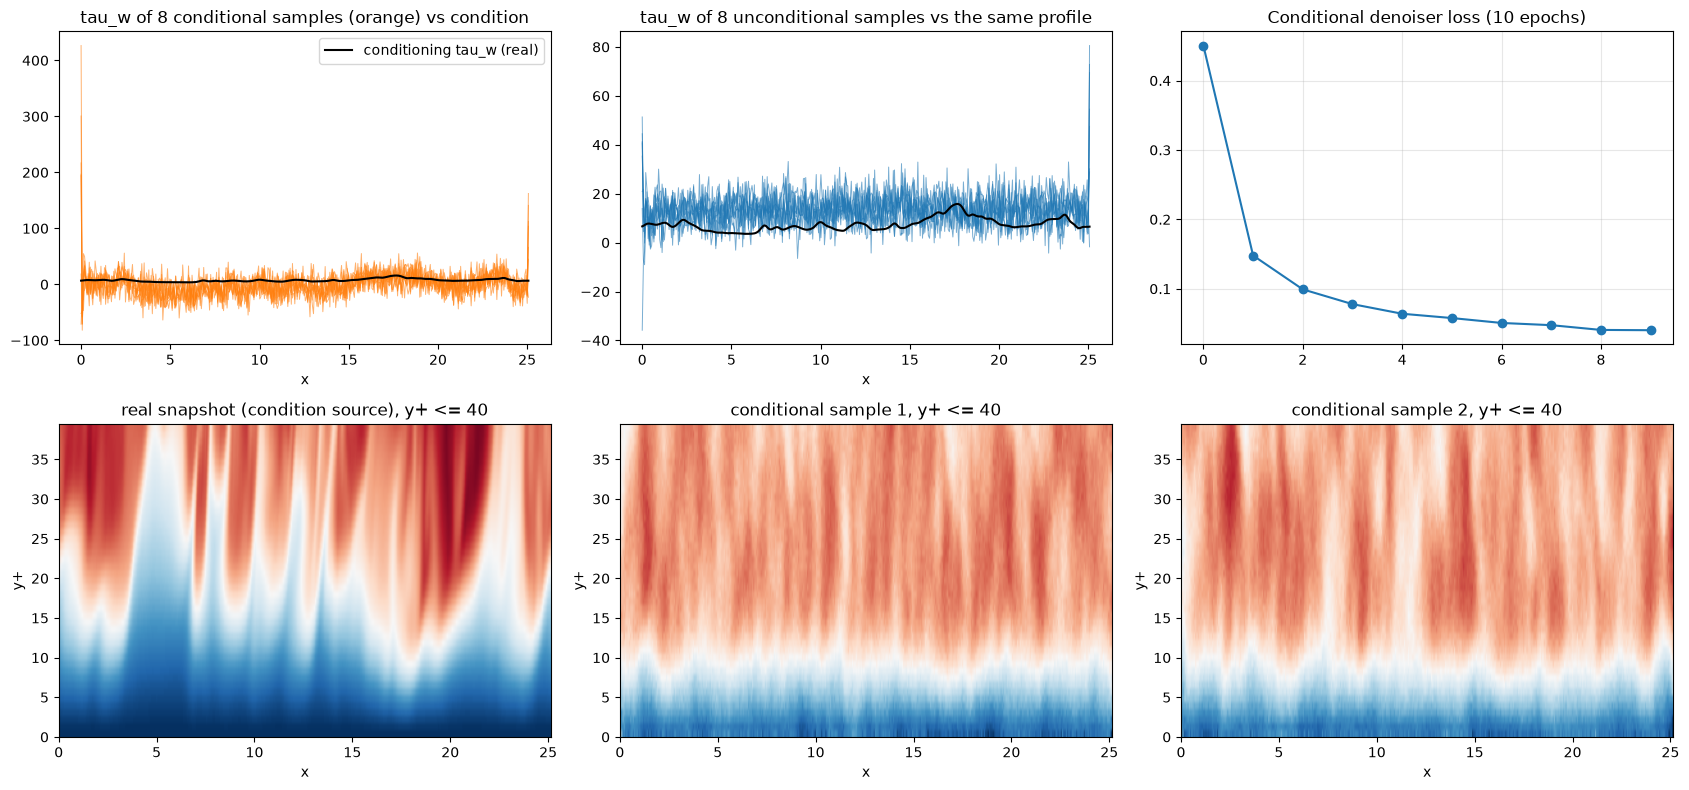

Result (Exercise 2): 10-epoch conditional model (5.3 min training, 9 s for 32 samples): corr(tau_w of sample, condition) = 0.309 (no-slip imposed: 0.089) vs unconditional 0.000 (0.063); relative RMS error 8.07 vs 3.06; sample-to-sample std at y+~10 = 0.36 x real std


In [19]:
ex2_tau = ex_tau_bottom(fields[:, :3, :, 0]).astype(np.float32)            # (N, n_x), physical
ex2_tmu, ex2_tsd = float(ex2_tau.mean()), float(ex2_tau.std())
ex2_tau_n = ((ex2_tau - ex2_tmu) / ex2_tsd).astype(np.float32)
print(f"tau_w: mean {ex2_tmu:.4f}, std {ex2_tsd:.4f}")

tf.keras.utils.set_random_seed(2)
ex2_model = create_denoiser((n_y_padded, n_x, 2), base_filters=16)
ex2_hist, ex2_secs = ex_train(ex2_model, beta, epochs=10, cond=ex2_tau_n[trn_idx], seed=2, label="cond")

ex2_targets = val_idx[:4]
ex2_cond = np.repeat(ex2_tau_n[ex2_targets], 8, axis=0)                   # 4 conditions x 8 samples
t0 = time.time()
ex2_samples = ex_phys(ex_sample(ex2_model, beta, 32, seed=22, cond=ex2_cond))
ex2_samp_secs = time.time() - t0


def ex2_scores(tau_gen, tau_tgt):
    c = np.corrcoef(tau_gen, tau_tgt)[0, 1]
    return c, np.sqrt(np.mean((tau_gen - tau_tgt) ** 2)) / tau_tgt.std()


ex2_rows = []
for noslip in (False, True):
    tg = ex_tau_bottom(ex2_samples, noslip); tu = ex_tau_bottom(ex_gen, noslip)
    for k, j in enumerate(ex2_targets):
        tgt = ex2_tau[j]
        for i in range(8):
            ex2_rows.append(dict(model="conditional", noslip=noslip, cond=k, **dict(zip(("corr", "rel_rmse"), ex2_scores(tg[k * 8 + i], tgt)))))
        for i in range(tu.shape[0]):
            ex2_rows.append(dict(model="unconditional", noslip=noslip, cond=k, **dict(zip(("corr", "rel_rmse"), ex2_scores(tu[i], tgt)))))
ex2_df = pd.DataFrame(ex2_rows)
ex2_sum = ex2_df.groupby(["model", "noslip"])[["corr", "rel_rmse"]].mean()
ex2_sum.to_csv(ex_dir / "ex2_conditioning_scores.csv"); print(ex2_sum.round(3))

# diversity: sample-to-sample std at y+~10 among the 8 samples of one condition, relative to the real std there
ex2_div = np.mean([ex2_samples[k * 8:(k + 1) * 8, ex_j10, :].std(axis=0).mean() for k in range(4)]) / std_profile_real[ex_j10]

ex_xg = np.arange(n_x) * ex_dx
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for i in range(8):
    ax[0, 0].plot(ex_xg, ex_tau_bottom(ex2_samples)[i], color="C1", lw=0.7, alpha=0.6)
ax[0, 0].plot(ex_xg, ex2_tau[ex2_targets[0]], color="k", lw=1.5, label="conditioning tau_w (real)")
ax[0, 0].set_title("tau_w of 8 conditional samples (orange) vs condition"); ax[0, 0].legend(); ax[0, 0].set_xlabel("x")
for i in range(8):
    ax[0, 1].plot(ex_xg, ex_tau_bottom(ex_gen)[i], color="C0", lw=0.7, alpha=0.6)
ax[0, 1].plot(ex_xg, ex2_tau[ex2_targets[0]], color="k", lw=1.5)
ax[0, 1].set_title("tau_w of 8 unconditional samples vs the same profile"); ax[0, 1].set_xlabel("x")
ax[0, 2].plot(ex2_hist, marker="o"); ax[0, 2].set_title("Conditional denoiser loss (10 epochs)"); ax[0, 2].grid(alpha=0.3)
ex2_near = ex_yp_bot <= 40
ex2_real0 = fields[ex2_targets[0], :n_y_raw, :, 0]
for c, (img, ttl) in enumerate([(ex2_real0, "real snapshot (condition source)"),
                                (ex2_samples[0], "conditional sample 1"), (ex2_samples[1], "conditional sample 2")]):
    ax[1, c].imshow(img[ex2_near], cmap="RdBu_r", aspect="auto", origin="lower", vmin=ex_vmin, vmax=ex_vmax,
                    extent=[0, ex_Lx, 0, ex_yp_bot[ex2_near].max()])
    ax[1, c].set_title(ttl + ", y+ <= 40"); ax[1, c].set_xlabel("x"); ax[1, c].set_ylabel("y+")
fig.tight_layout(); fig.savefig(ex_dir / "ex2_conditional_samples.png", dpi=100); plt.show()

ex2_c = ex2_sum["corr"]; ex2_e = ex2_sum["rel_rmse"]
print(f"Result (Exercise 2): 10-epoch conditional model ({ex2_secs/60:.1f} min training, {ex2_samp_secs:.0f} s for 32 samples): "
      f"corr(tau_w of sample, condition) = {ex2_c[('conditional', False)]:.3f} (no-slip imposed: {ex2_c[('conditional', True)]:.3f}) "
      f"vs unconditional {ex2_c[('unconditional', False)]:.3f} ({ex2_c[('unconditional', True)]:.3f}); relative RMS error "
      f"{ex2_e[('conditional', False)]:.2f} vs {ex2_e[('unconditional', False)]:.2f}; sample-to-sample std at y+~10 = {ex2_div:.2f} x real std")

## Experiment 3 — solution
The deterministic DDIM sampler ($\eta=0$) reuses the trained `denoiser`: from $\epsilon_\theta(x_t,t)$ it forms $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta)/\sqrt{\bar\alpha_t}$ and jumps to the next retained step with $x_{t'}=\sqrt{\bar\alpha_{t'}}\,\hat x_0+\sqrt{1-\bar\alpha_{t'}}\,\epsilon_\theta$. It is run with 10, 20 and 50 steps and compared with the full 200-step DDPM sampler (the original DDPM update, through the same compiled network call), on 64 samples each from the same seed. Quality = mean- and std-profile MAE against the real ensemble, and log-spectral distance of the band-averaged streamwise spectra; speed = wall time after a warm-up call.

{'sampler': 'DDPM 200', 'network_calls': 200, 'seconds_64': 15.513404846191406, 'mean_mae': 0.19138628244400024, 'std_mae': 0.029842855408787727, 'lsd': 6.10061325591348}


{'sampler': 'DDIM 50', 'network_calls': 50, 'seconds_64': 3.775294065475464, 'mean_mae': 0.21560809016227722, 'std_mae': 0.031155114993453026, 'lsd': 6.033687043968838}


{'sampler': 'DDIM 20', 'network_calls': 20, 'seconds_64': 1.5099542140960693, 'mean_mae': 0.21498483419418335, 'std_mae': 0.03125225380063057, 'lsd': 6.036410844089839}


{'sampler': 'DDIM 10', 'network_calls': 10, 'seconds_64': 0.7610509395599365, 'mean_mae': 0.2151302844285965, 'std_mae': 0.031456172466278076, 'lsd': 6.05482288995687}
 sampler  network_calls  seconds_64  mean_mae  std_mae    lsd
DDPM 200            200     15.5134    0.1914   0.0298 6.1006
 DDIM 50             50      3.7753    0.2156   0.0312 6.0337
 DDIM 20             20      1.5100    0.2150   0.0313 6.0364
 DDIM 10             10      0.7611    0.2151   0.0315 6.0548


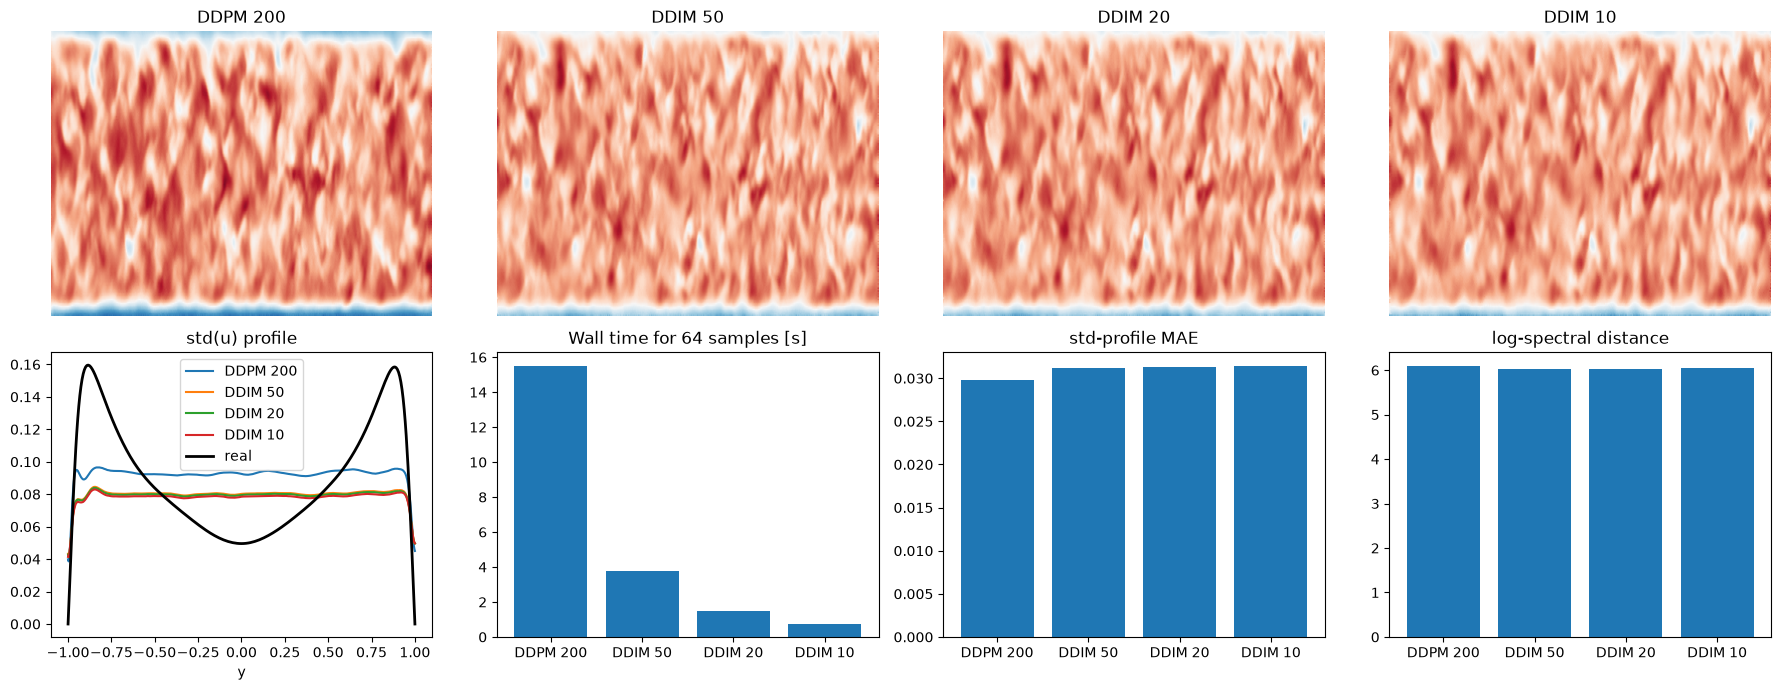

Result (Exercise 3): DDPM 200: 15.5 s, mean MAE 0.1914, std MAE 0.0298, LSD 6.101; DDIM 50: 3.8 s, mean MAE 0.2156, std MAE 0.0312, LSD 6.034; DDIM 20: 1.5 s, mean MAE 0.2150, std MAE 0.0313, LSD 6.036; DDIM 10: 0.8 s, mean MAE 0.2151, std MAE 0.0315, LSD 6.055; DDIM-20 speed-up 10.3x


In [20]:
_ = ex_call(denoiser, tf.zeros((64, n_y_padded, n_x, 1)), tf.zeros((64,)))   # warm-up / tracing
ex3_rows, ex3_samples = [], {}
for name, kw in [("DDPM 200", dict(method="ddpm")), ("DDIM 50", dict(method="ddim", steps=50)),
                 ("DDIM 20", dict(method="ddim", steps=20)), ("DDIM 10", dict(method="ddim", steps=10))]:
    t0 = time.time()
    s = ex_phys(ex_sample(denoiser, beta, 64, seed=3, **kw))
    secs = time.time() - t0
    ex3_samples[name] = s
    ex3_rows.append(dict(sampler=name, network_calls=200 if kw["method"] == "ddpm" else kw["steps"], seconds_64=secs, **ex_quality(s)))
    print(ex3_rows[-1])
ex3_df = pd.DataFrame(ex3_rows); ex3_df.to_csv(ex_dir / "ex3_ddim_vs_ddpm.csv", index=False)
print(ex3_df.round(4).to_string(index=False))

fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for c, (name, s) in enumerate(ex3_samples.items()):
    ax[0, c].imshow(s[0], cmap="RdBu_r", aspect="auto", origin="lower", vmin=ex_vmin, vmax=ex_vmax); ax[0, c].set_title(name); ax[0, c].axis("off")
    ax[1, 0].plot(y_grid, s.std(axis=(0, 2)), label=name)
ax[1, 0].plot(y_grid, std_profile_real, "k", lw=2, label="real"); ax[1, 0].set_title("std(u) profile"); ax[1, 0].legend(); ax[1, 0].set_xlabel("y")
ax[1, 1].bar(ex3_df["sampler"], ex3_df["seconds_64"]); ax[1, 1].set_title("Wall time for 64 samples [s]")
ax[1, 2].bar(ex3_df["sampler"], ex3_df["std_mae"]); ax[1, 2].set_title("std-profile MAE")
ax[1, 3].bar(ex3_df["sampler"], ex3_df["lsd"]); ax[1, 3].set_title("log-spectral distance")
fig.tight_layout(); fig.savefig(ex_dir / "ex3_ddim_vs_ddpm.png", dpi=100); plt.show()

ex3_d = ex3_df.set_index("sampler")
print("Result (Exercise 3): " + "; ".join(
    f"{k}: {r.seconds_64:.1f} s, mean MAE {r.mean_mae:.4f}, std MAE {r.std_mae:.4f}, LSD {r.lsd:.3f}" for k, r in ex3_d.iterrows())
    + f"; DDIM-20 speed-up {ex3_d.loc['DDPM 200','seconds_64']/ex3_d.loc['DDIM 20','seconds_64']:.1f}x")

## Experiment 4 — solution
Three models with the same U-Net and optimiser are trained for **10 epochs each (reduced budget; the base training uses 40)** so that they are comparable with one another: the base linear schedule with $T=200$ (control), the cosine schedule of Nichol and Dhariwal ($\bar\alpha_t=\cos^2\!\big(\tfrac{t/T+s}{1+s}\tfrac{\pi}{2}\big)/\bar\alpha_0$, $s=0.008$, $\beta_t\le0.999$) with $T=200$, and the cosine schedule with $T=500$. Each is sampled with its full $T$-step DDPM (64 samples). Because the cosine schedule ends with $\beta_t$ close to 1, all three use the same DDPM update written through $\hat x_0$ clipped to the range of the normalised training data (the usual practice; without clipping it is identical to the original DDPM update). Note that the training losses of different schedules are not directly comparable, since they weight the noise levels differently. The base 40-epoch model (Section 10 samples) is listed for reference.

[linear T=200] epoch 1/10 loss=0.5124


[linear T=200] epoch 2/10 loss=0.1885


[linear T=200] epoch 3/10 loss=0.1294


[linear T=200] epoch 4/10 loss=0.0946


[linear T=200] epoch 5/10 loss=0.0766


...

[cosine T=500] epoch 7/10 loss=0.0398


[cosine T=500] epoch 8/10 loss=0.0357


[cosine T=500] epoch 9/10 loss=0.0356


[cosine T=500] epoch 10/10 loss=0.0330


{'config': 'cosine, T=500, 10 epochs', 'T': 500, 'epochs': 10, 'train_min': 5.281236517429352, 'sample_s': 41.113816261291504, 'final_loss': 0.03299575524834486, 'mean_mae': 0.16301454603672028, 'std_mae': 0.0667140930891037, 'lsd': 6.404137742625585}
                                                     config   T  epochs  train_min  sample_s  final_loss  mean_mae  std_mae    lsd
base model: linear, T=200, 40 epochs (Section 10 sampler) 200      40        NaN       NaN      0.0162    0.1920   0.0303 6.1221
                                   linear, T=200, 10 epochs 200      10     5.2562   16.0461      0.0424    0.2010   0.0349 6.4099
                                   cosine, T=200, 10 epochs 200      10     5.2568   16.1700      0.0323    0.0909   0.0288 6.4245
                                   cosine, T=500, 10 epochs 500      10     5.2812   41.1138      0.0330    0.1630   0.0667 6.4041


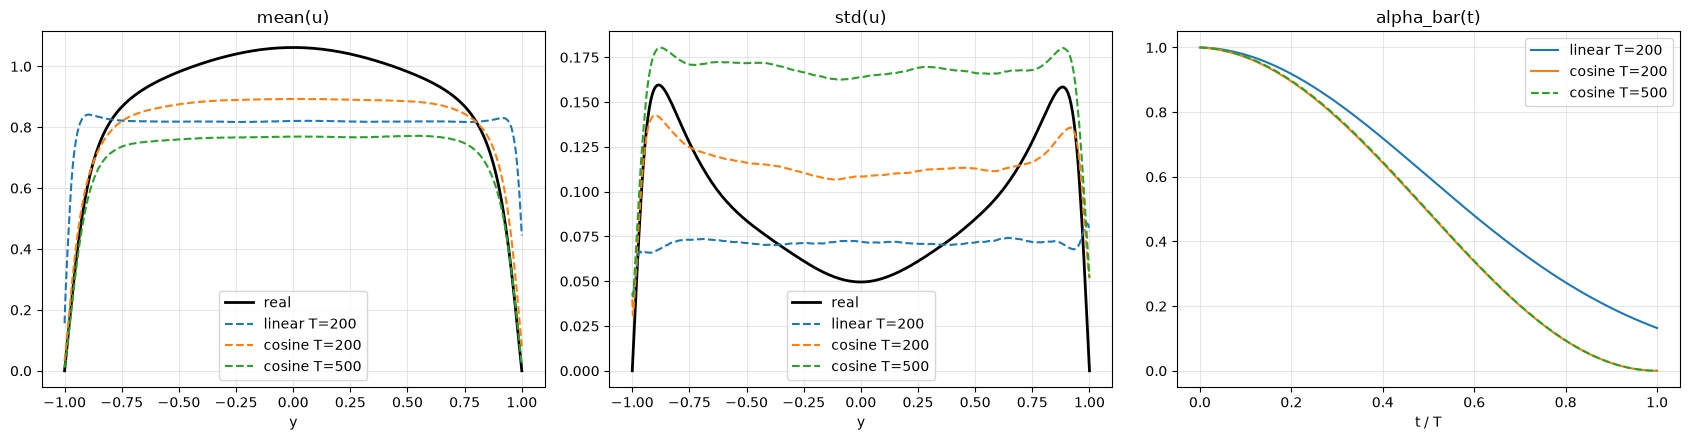

Result (Exercise 4, 10-epoch models): linear T=200: mean MAE 0.2010, std MAE 0.0349, LSD 6.410, train 5.3 min, sampling 16 s; cosine T=200: mean MAE 0.0909, std MAE 0.0288, LSD 6.424, train 5.3 min, sampling 16 s; cosine T=500: mean MAE 0.1630, std MAE 0.0667, LSD 6.404, train 5.3 min, sampling 41 s; base 40-epoch linear model: mean MAE 0.1920, std MAE 0.0303


In [21]:
def ex_cosine_beta(T_, s=0.008):
    tt = np.arange(T_ + 1) / T_
    f = np.cos((tt + s) / (1 + s) * np.pi / 2) ** 2
    ab = f / f[0]
    return np.clip(1.0 - ab[1:] / ab[:-1], 0.0, 0.999).astype(np.float32)


ex4_rows = [dict(config="base model: linear, T=200, 40 epochs (Section 10 sampler)", T=T, epochs=epochs,
                 train_min=np.nan, sample_s=np.nan, final_loss=float(loss_history[-1]), **ex_quality(ex_gen))]
ex4_profiles = {}
for k, (sched, T_) in enumerate([("linear", 200), ("cosine", 200), ("cosine", 500)]):
    b_ = np.linspace(1e-4, 0.02, T_).astype(np.float32) if sched == "linear" else ex_cosine_beta(T_)
    tf.keras.utils.set_random_seed(40 + k)
    m_ = create_denoiser(input_shape, base_filters=16)
    h_, secs_ = ex_train(m_, b_, epochs=10, seed=40 + k, label=f"{sched} T={T_}")
    _ = ex_call(m_, tf.zeros((64, n_y_padded, n_x, 1)), tf.zeros((64,)))
    t0 = time.time()
    s_ = ex_phys(ex_sample(m_, b_, 64, seed=4, x0_clip=ex_clip))
    ss_ = time.time() - t0
    ex4_profiles[f"{sched} T={T_}"] = (s_.mean(axis=(0, 2)), s_.std(axis=(0, 2)))
    ex4_rows.append(dict(config=f"{sched}, T={T_}, 10 epochs", T=T_, epochs=10, train_min=secs_ / 60, sample_s=ss_,
                         final_loss=h_[-1], **ex_quality(s_)))
    print(ex4_rows[-1])
    del m_
ex4_df = pd.DataFrame(ex4_rows); ex4_df.to_csv(ex_dir / "ex4_schedules.csv", index=False)
print(ex4_df.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(y_grid, mean_profile_real, "k", lw=2, label="real"); ax[1].plot(y_grid, std_profile_real, "k", lw=2, label="real")
for name, (mp, sp) in ex4_profiles.items():
    ax[0].plot(y_grid, mp, "--", label=name); ax[1].plot(y_grid, sp, "--", label=name)
ax[0].set_title("mean(u)"); ax[1].set_title("std(u)")
for a in ax[:2]: a.set_xlabel("y"); a.legend(); a.grid(alpha=0.3)
bt = np.linspace(1e-4, 0.02, 200); ax[2].plot(np.linspace(0, 1, 200), np.cumprod(1 - bt), label="linear T=200")
ax[2].plot(np.linspace(0, 1, 200), np.cumprod(1 - ex_cosine_beta(200)), label="cosine T=200")
ax[2].plot(np.linspace(0, 1, 500), np.cumprod(1 - ex_cosine_beta(500)), "--", label="cosine T=500")
ax[2].set_xlabel("t / T"); ax[2].set_title("alpha_bar(t)"); ax[2].legend(); ax[2].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(ex_dir / "ex4_schedules.png", dpi=100); plt.show()

print("Result (Exercise 4, 10-epoch models): " + "; ".join(
    f"{r.config.split(',')[0]} T={r['T']}: mean MAE {r.mean_mae:.4f}, std MAE {r.std_mae:.4f}, LSD {r.lsd:.3f}, "
    f"train {r.train_min:.1f} min, sampling {r.sample_s:.0f} s" for _, r in ex4_df.iloc[1:].iterrows())
    + f"; base 40-epoch linear model: mean MAE {ex4_df.loc[0,'mean_mae']:.4f}, std MAE {ex4_df.loc[0,'std_mae']:.4f}")

## Experiment 5 — solution
Streamwise energy spectra $E(k_x)=\langle|\hat u'(k_x)|^2\rangle/n_x^2$ (FFT in $x$, averaged over snapshots and over rows in four $y^+$ bands measured from the nearest wall: 0–10, 10–30, 30–70, 70–125) for the real ensemble (512 snapshots), the 64 DDPM samples of Section 10, the 64 DDIM-50 samples of Experiment 3, and the Gaussian baseline of Experiment 1 for reference. The ratio generated/real is summarised at large scales (modes 1–8) and small scales (modes 64–192), and by the first mode at which the ratio leaves the band [0.5, 2].

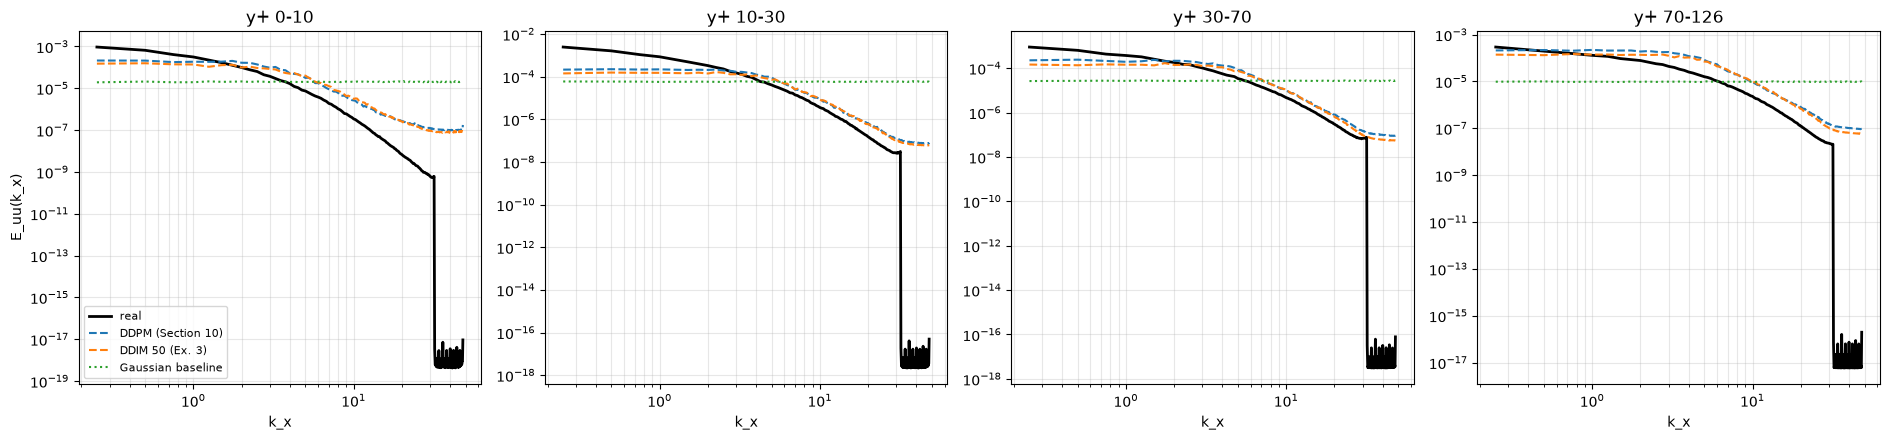

  band          ensemble  ratio_modes_1_8  ratio_modes_64_192  first_mode_outside_factor2
  0-10 DDPM (Section 10)            0.853        8.368450e+10                           1
  0-10   DDIM 50 (Ex. 3)            0.559        6.697378e+10                           1
  0-10 Gaussian baseline            0.095        1.669369e+13                           1
 10-30 DDPM (Section 10)            0.324        1.369766e+10                           1
 10-30   DDIM 50 (Ex. 3)            0.226        1.101267e+10                           1
 10-30 Gaussian baseline            0.089        9.736066e+12                           1
 30-70 DDPM (Section 10)            0.674        1.182379e+10                           1
 30-70   DDIM 50 (Ex. 3)            0.457        7.300687e+09                           1
 30-70 Gaussian baseline            0.085        3.162138e+12                           1
70-126 DDPM (Section 10)            1.712        6.477095e+09                           6
70-126   D

In [22]:
ex5_sets = {"DDPM (Section 10)": ex_gen, "DDIM 50 (Ex. 3)": ex3_samples["DDIM 50"], "Gaussian baseline": ex1_gauss}
ex5_Eb = {k: ex_band_spec(ex_spec(u)) for k, u in ex5_sets.items()}
ex5_kx = 2 * np.pi * np.arange(n_x // 2 + 1) / ex_Lx

fig, ax = plt.subplots(1, 4, figsize=(19, 4.5))
ex5_rows = []
for b, (lo, hi) in enumerate(ex_bands):
    ax[b].loglog(ex5_kx[1:], ex_Eb_real[b, 1:], "k", lw=2, label="real")
    for k, Eb in ex5_Eb.items():
        ax[b].loglog(ex5_kx[1:], Eb[b, 1:], ":" if "Gaussian" in k else "--", label=k)
        ratio = Eb[b, 1:] / ex_Eb_real[b, 1:]
        bad = np.where(np.abs(np.log10(ratio)) > np.log10(2))[0]
        ex5_rows.append(dict(band=f"{lo}-{hi}", ensemble=k, ratio_modes_1_8=float(ratio[:8].mean()),
                             ratio_modes_64_192=float(ratio[63:].mean()),
                             first_mode_outside_factor2=int(bad[0] + 1) if len(bad) else None))
    ax[b].set_title(f"y+ {lo}-{hi}"); ax[b].set_xlabel("k_x"); ax[b].grid(alpha=0.3, which="both")
ax[0].set_ylabel("E_uu(k_x)"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(ex_dir / "ex5_spectra.png", dpi=100); plt.show()
ex5_df = pd.DataFrame(ex5_rows); ex5_df.to_csv(ex_dir / "ex5_spectra_ratios.csv", index=False)
print(ex5_df.round(3).to_string(index=False))
ex5_d = ex5_df[ex5_df.ensemble == "DDPM (Section 10)"].set_index("band")
print("Result (Exercise 5): DDPM/real energy ratio, modes 1-8 | modes 64-192 | first mode outside x2: " + "; ".join(
    f"y+ {bnd}: {r.ratio_modes_1_8:.2f} | {r.ratio_modes_64_192:.2f} | {r.first_mode_outside_factor2}" for bnd, r in ex5_d.iterrows()))

## Summary of the experiment solutions
- **Experiment 1:** the per-row Gaussian baseline matches the profiles but has, by construction, no spatial correlation (independent pixels); the diffusion samples' correlation lengths and spectral distance are compared with the real ones in the printed Result line.
- **Experiment 2:** a conditional denoiser with $\tau_w(x)$ as a second channel (10 epochs, reduced budget); the correlation between the conditioning profile and the samples' own wall stress, against the unconditional model, and the remaining sample-to-sample spread are in the Result line.
- **Experiment 3:** deterministic DDIM with 10, 20 and 50 steps on the base denoiser versus 200-step DDPM; times and quality measures in the Result line and `ex3_ddim_vs_ddpm.csv`.
- **Experiment 4:** linear $T=200$, cosine $T=200$ and cosine $T=500$ at 10 epochs each (reduced budget), same clipped DDPM sampler; profile MAE, spectral distance and time costs in the Result line and `ex4_schedules.csv`.
- **Experiment 5:** band-averaged streamwise spectra, real versus generated; large- and small-scale energy ratios and the first mode outside a factor 2 per band in the Result line and `ex5_spectra_ratios.csv`.

# Animation — the diffusion model learning channel-flow fields
The snapshots come from **the base training** (hook cell before the training cell; no second run): every half epoch the per-step losses so far and 32 fields generated from the same fixed noise with a 20-step deterministic DDIM sampler (for the snapshots only; the base training's samples use its 200-step DDPM sampler). Dashboard: `../animations/01_training_dashboard.mp4`; last frame: `../animations/01_final_frame.png`.

In [23]:
import time
from pathlib import Path
import numpy as np
import tensorflow as tf

anim_dir = Path("../animations"); anim_dir.mkdir(exist_ok=True)
snaps_info = f"{len(anim_snaps)} snapshots during the base training, of which sampling took {anim_snap_secs/60:.1f} min"
print(snaps_info)

81 snapshots during the base training, of which sampling took 1.2 min


In [24]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()

anim_all_l = np.array(anim_snaps[-1]["losses"])
anim_win = min(100, len(anim_all_l))
anim_smooth = np.convolve(anim_all_l, np.ones(anim_win) / anim_win, mode="valid")
anim_vmin, anim_vmax = np.percentile(fields[:16, :n_y_raw, :, 0], [1, 99])
anim_gap = np.full((6, n_x), np.nan)
anim_std_max = max(std_profile_real.max(), np.percentile([s["std"].max() for s in anim_snaps], 90)) * 1.15
anim_mean_lo = min(mean_profile_real.min(), np.percentile([s["mean"].min() for s in anim_snaps], 10))
anim_mean_hi = max(mean_profile_real.max(), np.percentile([s["mean"].max() for s in anim_snaps], 90))
anim_pad = 0.1 * (anim_mean_hi - anim_mean_lo)
anim_n_steps = anim_snaps[-1]["step"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))


def anim_draw(k):
    s = anim_snaps[k]
    for a in axes.ravel():
        a.clear()
    ax = axes[0, 0]
    if s["losses"]:
        ax.plot(np.arange(1, len(s["losses"]) + 1), s["losses"], color="0.75", lw=0.5, label="per step")
        n_sm = len(s["losses"]) - anim_win + 1
        if n_sm > 0:
            ax.plot(np.arange(anim_win, len(s["losses"]) + 1), anim_smooth[:n_sm], color="C0", lw=1.5, label=f"{anim_win}-step mean")
    ax.set_xlim(0, anim_n_steps); ax.set_ylim(0, np.percentile(anim_all_l, 99.5) * 1.05)
    ax.set_xlabel("training step (batch of 16)"); ax.set_ylabel("noise-prediction MSE")
    ax.set_title(f"Training loss, epoch {s['epoch']:.1f} of {epochs}"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
    img = np.vstack([s["fields"][0], anim_gap, s["fields"][1], anim_gap, s["fields"][2]])
    axes[0, 1].imshow(img, cmap="RdBu_r", aspect="auto", origin="lower", vmin=anim_vmin, vmax=anim_vmax)
    axes[0, 1].axis("off"); axes[0, 1].set_title(f"Three samples u(y, x) from fixed noise (DDIM, {ANIM_DDIM_STEPS} steps)")
    axes[1, 0].plot(y_grid, mean_profile_real, "k", lw=2, label="real ensemble")
    axes[1, 0].plot(y_grid, s["mean"], "C3--", lw=1.5, label=f"{ANIM_N} generated")
    axes[1, 0].set_ylim(anim_mean_lo - anim_pad, anim_mean_hi + anim_pad)
    axes[1, 0].set_xlabel("y"); axes[1, 0].set_ylabel("mean(u)"); axes[1, 0].set_title("Mean profile")
    axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)
    axes[1, 1].plot(y_grid, std_profile_real, "k", lw=2, label="real ensemble")
    axes[1, 1].plot(y_grid, s["std"], "C3--", lw=1.5, label=f"{ANIM_N} generated")
    axes[1, 1].set_ylim(0, anim_std_max)
    axes[1, 1].set_xlabel("y"); axes[1, 1].set_ylabel("std(u)"); axes[1, 1].set_title("Standard-deviation profile")
    axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)
    fig.suptitle("DDPM on channel-flow u(y, x) planes, the base training")
    fig.tight_layout()


anim_draw(len(anim_snaps) - 1); fig.savefig(anim_dir / "01_final_frame.png", dpi=110)
ani = FuncAnimation(fig, anim_draw, frames=len(anim_snaps))
ani.save(anim_dir / "01_training_dashboard.mp4", writer=FFMpegWriter(fps=6, bitrate=2400), dpi=100)
plt.close(fig)
anim_last = anim_snaps[-1]
print(f"Animation: {len(anim_snaps)} frames -> {anim_dir/'01_training_dashboard.mp4'}; final frame -> "
      f"{anim_dir/'01_final_frame.png'}; final-frame profile MAE: mean "
      f"{np.mean(np.abs(anim_last['mean']-mean_profile_real)):.4f}, std {np.mean(np.abs(anim_last['std']-std_profile_real)):.4f}")

Animation: 81 frames -> ../animations/01_training_dashboard.mp4; final frame -> ../animations/01_final_frame.png; final-frame profile MAE: mean 0.2252, std 0.0312


**What the animation shows.** Top left: the noise-prediction loss of the base training, step by step (grey) and as a 100-step running mean (blue); its level alone says little about sample quality, which is why the other three panels are shown. Top right: three fields generated at each snapshot from the same fixed noise with a 20-step deterministic DDIM sampler; at the first frame (untrained network) they are unstructured, and the frames show when the mean shear between the walls and streamwise-elongated near-wall streaks appear. Bottom: the mean and standard-deviation profiles of 32 such fields (dashed) against the real ensemble (solid); the panels show how quickly each profile approaches the real one, and the final-frame MAEs are printed by the cell above. The snapshot samples use DDIM with 20 steps, not the base 200-step DDPM sampler, so their quality is indicative of the training progress rather than identical to Section 10's samples.

# Three-seed repeats
The notebook's denoiser training (40 epochs, about 19 minutes on the Apple GPU) is longer than 15 minutes, so it is **a single run** (seed 0, the base run). The experiment trainings (10 epochs each, about 5 minutes) are repeated with the seeds 1 and 2: the conditional denoiser of Experiment 2 and the three schedules of Experiment 4, each trained from `tf.keras.utils.set_random_seed` with the new seed and sampled from a new noise seed; the samplers of Experiment 3 are re-run on the base denoiser with new noise seeds (no training). One cell per seed, then a summary.

In [25]:
# Three-seed repeats: helpers
seed_rows = []
def seed_run(seed):
    rows = []
    def add(part, config, **v): rows.append(dict(seed=seed, part=part, config=config, **v)); print(rows[-1], flush=True)
    # Exercise 2: conditional denoiser
    tf.keras.utils.set_random_seed(2 + 100 * seed)
    m2 = create_denoiser((n_y_padded, n_x, 2), base_filters=16)
    h2, s2 = ex_train(m2, beta, epochs=10, cond=ex2_tau_n[trn_idx], seed=2 + 100 * seed, label=f"cond s{seed}")
    smp = ex_phys(ex_sample(m2, beta, 32, seed=22 + 100 * seed, cond=ex2_cond))
    tg = ex_tau_bottom(smp)
    sc = [ex2_scores(tg[k * 8 + i], ex2_tau[j]) for k, j in enumerate(ex2_targets) for i in range(8)]
    add("Exercise 2", "conditional denoiser", corr=float(np.mean([c for c, _ in sc])), rel_rmse=float(np.mean([e for _, e in sc])), train_min=s2 / 60, final_loss=h2[-1])
    del m2
    # Exercise 3: samplers on the base denoiser, new noise seed
    for name, kw in [("DDPM 200", dict(method="ddpm")), ("DDIM 50", dict(method="ddim", steps=50)), ("DDIM 20", dict(method="ddim", steps=20)), ("DDIM 10", dict(method="ddim", steps=10))]:
        add("Exercise 3", name, **ex_quality(ex_phys(ex_sample(denoiser, beta, 64, seed=3 + 100 * seed, **kw))))
    # Exercise 4: three schedules, 10 epochs each
    for k, (sched, T_) in enumerate([("linear", 200), ("cosine", 200), ("cosine", 500)]):
        b_ = np.linspace(1e-4, 0.02, T_).astype(np.float32) if sched == "linear" else ex_cosine_beta(T_)
        tf.keras.utils.set_random_seed(40 + k + 100 * seed)
        m_ = create_denoiser(input_shape, base_filters=16)
        h_, secs_ = ex_train(m_, b_, epochs=10, seed=40 + k + 100 * seed, label=f"{sched} T={T_} s{seed}")
        add("Exercise 4", f"{sched}, T={T_}, 10 epochs", train_min=secs_ / 60, final_loss=h_[-1], **ex_quality(ex_phys(ex_sample(m_, b_, 64, seed=4 + 100 * seed, x0_clip=ex_clip))))
        del m_
    return rows
seed_rows.append(dict(seed=0, part="Exercise 2", config="conditional denoiser", corr=float(ex2_c[("conditional", False)]), rel_rmse=float(ex2_e[("conditional", False)]), train_min=ex2_secs / 60, final_loss=ex2_hist[-1]))
for r in ex3_df.itertuples(): seed_rows.append(dict(seed=0, part="Exercise 3", config=r.sampler, mean_mae=r.mean_mae, std_mae=r.std_mae, lsd=r.lsd))
for r in ex4_df.iloc[1:].itertuples(): seed_rows.append(dict(seed=0, part="Exercise 4", config=r.config, train_min=r.train_min, final_loss=r.final_loss, mean_mae=r.mean_mae, std_mae=r.std_mae, lsd=r.lsd))
print(len(seed_rows), "base-run (seed 0) rows")

8 base-run (seed 0) rows


In [26]:
# Seed 1
seed_rows += seed_run(1)

[cond s1] epoch 1/10 loss=0.4518


[cond s1] epoch 2/10 loss=0.1311


[cond s1] epoch 3/10 loss=0.0926


[cond s1] epoch 4/10 loss=0.0706


[cond s1] epoch 5/10 loss=0.0605


...

[cosine T=500 s1] epoch 7/10 loss=0.0393


[cosine T=500 s1] epoch 8/10 loss=0.0380


[cosine T=500 s1] epoch 9/10 loss=0.0357


[cosine T=500 s1] epoch 10/10 loss=0.0324


{'seed': 1, 'part': 'Exercise 4', 'config': 'cosine, T=500, 10 epochs', 'train_min': 5.303107662995656, 'final_loss': 0.03244812540136851, 'mean_mae': 0.18545502424240112, 'std_mae': 0.04663647711277008, 'lsd': 6.446211520327621}


In [27]:
# Seed 2
seed_rows += seed_run(2)

[cond s2] epoch 1/10 loss=0.3994


[cond s2] epoch 2/10 loss=0.1208


[cond s2] epoch 3/10 loss=0.0837


[cond s2] epoch 4/10 loss=0.0639


[cond s2] epoch 5/10 loss=0.0567


...

[cosine T=500 s2] epoch 7/10 loss=0.0455


[cosine T=500 s2] epoch 8/10 loss=0.0405


[cosine T=500 s2] epoch 9/10 loss=0.0399


[cosine T=500 s2] epoch 10/10 loss=0.0350


{'seed': 2, 'part': 'Exercise 4', 'config': 'cosine, T=500, 10 epochs', 'train_min': 5.31863352060318, 'final_loss': 0.035026919314494497, 'mean_mae': 0.11887793242931366, 'std_mae': 0.032134078443050385, 'lsd': 6.4180786297383134}


In [28]:
# Three-seed summary
seed_runs = pd.DataFrame(seed_rows); seed_runs.to_csv(ex_dir / "seeds_runs.csv", index=False)
cols = [c for c in ("corr", "rel_rmse", "mean_mae", "std_mae", "lsd", "final_loss") if c in seed_runs]
seed_sum = seed_runs.groupby(["part", "config"], sort=False)[cols].agg(["mean", "std", "min", "max"])
seed_sum.to_csv(ex_dir / "seeds_summary.csv")
pd.set_option("display.width", 250); print(seed_sum.round(4).to_string())

                                       corr                         rel_rmse                         mean_mae                         std_mae                             lsd                         final_loss                        
                                       mean     std     min     max     mean     std     min     max     mean     std     min     max    mean     std     min     max    mean     std     min     max       mean     std     min     max
part       config                                                                                                                                                                                                                       
Exercise 2 conditional denoiser      0.3247  0.2053  0.1277  0.5374   7.8634  0.2303  7.6142  8.0683      NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     0.0373  0.0047  0.0318  0.0403
Exercise 3 DDPM 200                     NaN     NaN     NaN     NaN 